# Ice-Free and IPO Relationship

**Just concentrating on the IPO alone, see if there's a relationship between the phase of the IPO in ice-free timing in both directions**


In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.patheffects as pe
import matplotlib.gridspec as gridspec
import numpy as np
import datetime
import scipy.signal as signal
import scipy.stats as stats
import os
import glob
import re
print(datetime.datetime.now())

2026-08-16 08:46:31.664806


# Read data

In [2]:
model_names = [
    'ACCESS-ESM1-5', 'CanESM5', 'CESM2-LENS', 'CESM2-LENS-SMBB', 'EC-Earth3',
    'MIROC6', 'MPI-ESM1-2-LR', 'CanESM2', 'CESM1', 'GFDL-ESM2M', 'MPI-ESM1',
]

In [3]:
#read the SIE data from all models
#N.B. r1i1p1f1 for CanESM5 does not have historical data
SIE_sep_GCMs = {}

for GCM_ in model_names:
    print(GCM_)
    
    SIE_model = []
    
    mem_list = np.ravel(np.sort([
        re.findall(f'SIA_SIE_{GCM_}_(.*)_historical_2100.nc', i) for i in 
        glob.glob('/glade/work/cwpowell/ice-free/'\
        f'sea_ice_data/SIA_SIE_{GCM_}_*_historical_2100.nc')
    ]))
    
    for mem_ in mem_list:
        temp_data = xr.open_dataset('/glade/work/cwpowell/ice-free/'\
            f'sea_ice_data/SIA_SIE_{GCM_}_{mem_}_historical_2100.nc')
        
        SIE_model.append(temp_data)
        
    SIE_model = xr.concat((SIE_model),dim='member')
    SIE_model['member'] = mem_list
    SIE_model = SIE_model['Arctic_SIE'].sel(time=SIE_model['time.month']==9)
    
    SIE_model['time'] = np.arange(int(SIE_model['time.year'].min().values),
                                  int(SIE_model['time.year'].max().values)+1)
    
    SIE_model = SIE_model.rename({'time':'year'})
    
    
    SIE_sep_GCMs[GCM_] = SIE_model

#drop CanESM5 r1i1p1f1 as no historical data
SIE_sep_GCMs['CanESM5'] = SIE_sep_GCMs['CanESM5'].drop_sel(member='r1i1p1f1')

ACCESS-ESM1-5
CanESM5
CESM2-LENS
CESM2-LENS-SMBB
EC-Earth3
MIROC6
MPI-ESM1-2-LR
CanESM2
CESM1
GFDL-ESM2M
MPI-ESM1


In [5]:
#calculate ice free year for 11 year running means
sep_SIE_11yr = {}

for model_name in model_names:
    sep_SIE_11yr[model_name] = SIE_sep_GCMs[model_name].rolling(
        year=11, center=True).mean()

#drop CanESM5 r1i1p1f1 as no historical data
#sep_SIE_11yr['CanESM5'] = sep_SIE_11yr['CanESM5'].drop_sel(member='r1i1p1f1')

In [6]:
#load the IPO derived from the TPI index
IPO_models = {}

base_path = '/glade/work/cwpowell/low-freq-trajectories/SST_for_IPO/IPO_per_Screen_Deser/'
# base_path = '/glade/work/cwpowell/ice-free/IPO/'

# file_name = '_11yr_annual_av_TPI_filtered_11yr_Lanczos.nc'#'_11yr_annual_av_TPI_13yr_Lanczos_filter.nc'
# file_name = '_annual_11yr_TPI.nc'
file_name = '_11yr_annual_av_TPI.nc'

for model_name in model_names:
    if model_name in ['CESM2-LENS','CESM2-LENS-SMBB']:
        temp = xr.open_dataarray(base_path+'CESM2-LENS'+file_name)
        
        IPO_models[model_name] = temp.sel(
            member=sep_SIE_11yr[model_name]['member'])
    
    elif model_name in ['CanESM2', 'CESM1', 'GFDL-ESM2M', 'MPI-ESM1']:
        temp = xr.open_dataarray(base_path+model_name+file_name)
        
        if model_name == 'MPI-ESM1':
            temp['member'] = ['r{}i2005p3'.format(str(mem_).zfill(3))
                              for mem_ in temp['member'].values]
        else:
            temp['member'] = [f'r{mem_}i1p1' for mem_ in temp['member'].values]
            
        IPO_models[model_name] = temp.sortby('member')
    
    else:
        IPO_models[model_name] = xr.open_dataarray(base_path+model_name+file_name)

#drop CanESM5 r1i1p1f1 as no historical SIE data
IPO_models['CanESM5'] = IPO_models['CanESM5'].drop_sel(member='r1i1p1f1')

#read observational data
HadISST_IPO = xr.open_dataarray('/glade/work/cwpowell/ice-free/IPO/'\
                              'HadISST1_annual_11yr_TPI.nc')

## Internal Variability of Ice-Free Years

In [ ]:
model_names_no_SMBB = np.sort(model_names.copy())
np.delete(model_names_no_SMBB, 3)

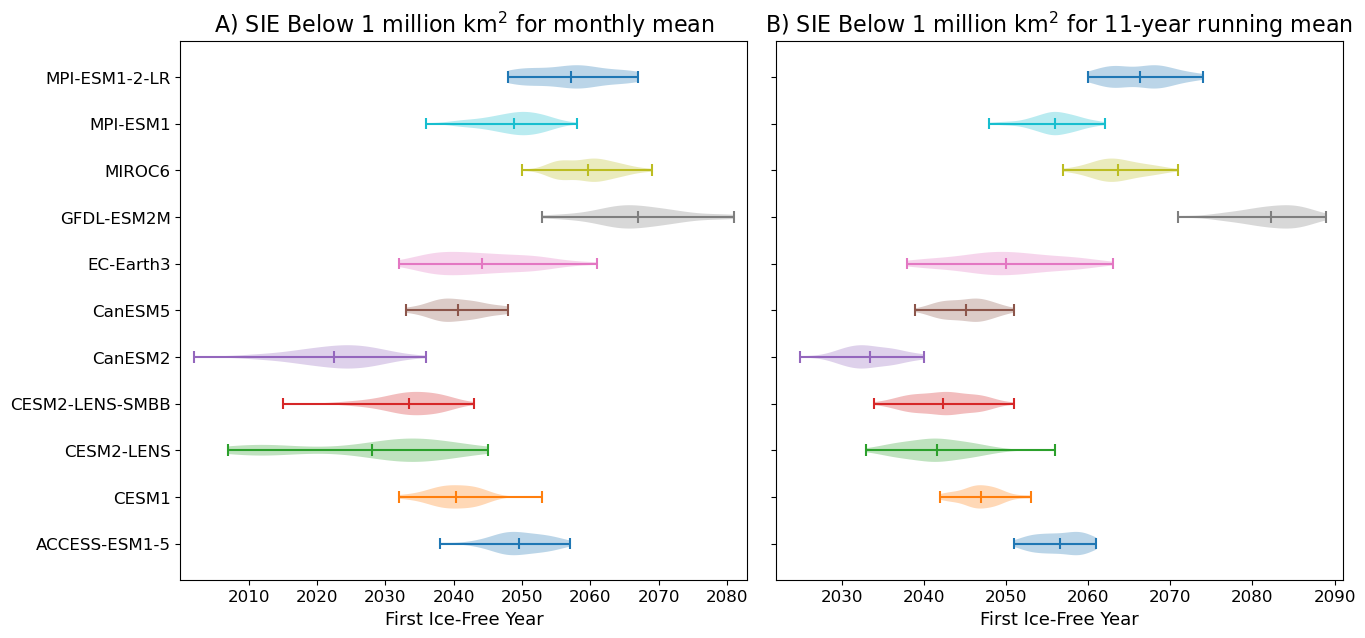

In [7]:
#both raw data and 11-year running means
fig, axes = plt.subplots(1,2,figsize=[15,7])

IF_ranges = []
for model_i, model_name in enumerate(model_names_no_SMBB):

    #load the correct model data
    data = SIE_sep_GCMs[model_name].copy().rolling(year=11, center=True).mean()
    
    if model_name == 'CanESM5':
        data = data.sel(year=slice(2015,2100))

    #calculate the first ice-free years
    IF_yrs = data['year'].where(data < 1).min('year')
    IF_ranges.append((max(IF_yrs)-min(IF_yrs)))
    
    axes[1].violinplot(np.ravel(IF_yrs.values), [model_i], vert=False,
                   showmeans=True)

axes[1].set_xlabel('First Ice-Free Year', fontsize=13);
axes[1].set_title(r'B) SIE Below 1 million km$^2$ for 11-year running mean', fontsize=16);
axes[1].set_xticks(np.arange(2030,2091,10))
axes[1].set_xticklabels(np.arange(2030,2091,10), fontsize=12)
axes[1].set_xlim(2022,2091);
axes[1].set_yticks(np.arange(len(model_names_no_SMBB)));
axes[1].set_yticklabels([])

IF_ranges = []
for model_i, model_name in enumerate(model_names_no_SMBB):

    #load the correct model data
    data = SIE_sep_GCMs[model_name].copy()
    
    if model_name == 'CanESM5':
        data = data.sel(year=slice(2015,2100))

    #calculate the first ice-free years
    IF_yrs = data['year'].where(data < 1).min('year')
    IF_ranges.append((max(IF_yrs)-min(IF_yrs)))
    
    axes[0].violinplot(np.ravel(IF_yrs.values), [model_i], vert=False,
                   showmeans=True)

axes[0].set_xlabel('First Ice-Free Year', fontsize=13);
axes[0].set_title(r'A) SIE Below 1 million km$^2$ for monthly mean', fontsize=16);
axes[0].set_yticks(np.arange(len(model_names_no_SMBB)));
axes[0].set_yticklabels(model_names_no_SMBB, fontsize=12)
axes[0].set_xticks(np.arange(2010,2081,10))
axes[0].set_xticklabels(np.arange(2010,2081,10), fontsize=12)
axes[0].set_xlim(2000,2083);

plt.subplots_adjust(wspace=0.05)
# plt.savefig('/glade/work/cwpowell/ice-free/figures/IF_range_LEs.pdf',bbox_inches='tight')


In [27]:
#calculate the time to ice-free from initial point of 4.7 and 4.6 million square km
time_47 = []
time_4586 = []
for model_i, model_name in enumerate(model_names_no_SMBB):

    #load the correct model data
    data = sep_SIE_11yr[model_name].copy()

    IF_yrs = data['year'].where(data < 1).min('year')
    yr_47 = data['year'].where(data < 4.7).min('year')
    yr_4586 = data['year'].where(data < 4.586).min('year')

    time_47.append(np.mean(yr_47-IF_yrs))
    time_4586.append(np.mean(yr_4586-IF_yrs))

In [35]:
#calculate the time to ice-free from initial point of 4.7 and 4.6 million square km
time_47 = []
time_4586 = []
for model_i, model_name in enumerate(model_names_no_SMBB):

    #load the correct model data
    data = SIE_sep_GCMs[model_name].copy()

    IF_yrs = data['year'].where(data < 1).min('year')
    yr_47 = data['year'].where(data < 4.7).min('year')
    yr_4586 = data['year'].where(data < 4.586).min('year')

    time_47.append(np.mean(yr_47-IF_yrs))
    time_4586.append(np.mean(yr_4586-IF_yrs))

In [36]:
np.mean(time_4586)

-39.83724180581323

In [37]:
np.mean(time_47)

-42.08899505256648

## IPO phase pooled

In [7]:
#N.B. comment out whether using persistence or 0.9 sigma threshold
#need to recalculate everything based on trajectories of 4.2-5.2 SIE in increments of 0.1 million sq km
IPO_pos_dict = {}
IPO_neg_dict = {}
IPO_pos_dict_m = {}
IPO_neg_dict_m = {}
SIE_all_mem = {}

# IPO_phase_th = 0.9

for model_name in model_names:
    print(model_name)

    #need to use this for persistence method
    if model_name in ['GFDL-ESM2M','MPI-ESM1']:
        continue

    IPO_pos_ = []
    IPO_neg_ = []
    IPO_pos_m = []
    IPO_pos_pos_mems = []
    IPO_pos_neg_mems = []
    IPO_pos_mems = []
    IPO_neg_m = []
    IPO_neg_pos_mems = []
    IPO_neg_neg_mems = []
    IPO_neg_mems = []
    SIE_mem_all_start = []
    
    for start_SIE in np.arange(4.2,5.21,0.1):
    # for start_SIE in np.arange(3.7,4.71,0.1):
        
        IPO_pos_mem = []
        IPO_neg_mem = []
        IPO_pos_mem_m = []
        IPO_neg_mem_m = []
        all_SIE_mem = []
        for mem_ in IPO_models[model_name]['member']:
            if mem_ == 'r49i1p1':
                continue
            
            #find latest matching year to SIE, define start_year
            start_yr_mem = int(sep_SIE_11yr[model_name]['year'].where(
                (sep_SIE_11yr[model_name].sel(member=mem_) - start_SIE) < 0).min('year'))

            #always append the SIE with years corrected to 0-51
            if model_name == 'CanESM2': #need as many years as possible
                mem_SIE_traj = sep_SIE_11yr[model_name].sel(member=mem_).sel(
                    year=slice(start_yr_mem,start_yr_mem+60))
                mem_SIE_traj['year'] = np.arange(0,61)
            else:
                mem_SIE_traj = sep_SIE_11yr[model_name].sel(member=mem_).sel(
                    year=slice(start_yr_mem,start_yr_mem+54))
                mem_SIE_traj['year'] = np.arange(0,55)
                
            all_SIE_mem.append(mem_SIE_traj)
            
            ###### persistence metric of 10+ years in same phase
            IPO_pos = (IPO_models[model_name].sel(member=mem_).sel(
                year=slice(start_yr_mem-9,start_yr_mem))>0).min('year')==True
            IPO_neg = (IPO_models[model_name].sel(member=mem_).sel(
                year=slice(start_yr_mem-9,start_yr_mem))<0).min('year')==True
            
            ###### S&D method of +/- 0.9
            # IPO_pos = IPO_models[model_name].sel(member=mem_).sel(year=start_yr_mem)>0.9
            # IPO_neg = IPO_models[model_name].sel(member=mem_).sel(year=start_yr_mem)<-0.9
            
            if IPO_pos:
                IPO_pos_mem.append(mem_SIE_traj)
                IPO_pos_mem_m.append(mem_SIE_traj-start_SIE)
                IPO_pos_mems.append(str(mem_.values))
            elif IPO_neg:
                IPO_neg_mem.append(mem_SIE_traj)
                IPO_neg_mem_m.append(mem_SIE_traj-start_SIE)
                IPO_neg_mems.append(str(mem_.values))
                
        
        #if no examples of both criteria being fulfilled, instead append the 
        #ensemble mean
        ens_mean = xr.concat((all_SIE_mem),dim='member').mean('member')
            
        #also collect up all the IPO pos/neg irrespective of PARC if length none
        # if len(IPO_pos_mem) < 1:
        #     IPO_pos_ = [ens_mean]
        #     IPO_pos_m = all_SIE_mem[0]*0 + ens_mean-start_SIE
        # if len(IPO_neg_mem) < 1:
        #     IPO_neg_ = [ens_mean]
        #     IPO_neg_m = all_SIE_mem[0]*0 + ens_mean-start_SIE
        
        #also calculate the standard deviation, if at least 2 trajectories        
        IPO_pos_.append(xr.concat((IPO_pos_mem),dim='member').mean('member'))
        IPO_neg_.append(xr.concat((IPO_neg_mem),dim='member').mean('member'))
      
        IPO_pos_m.append(xr.concat((IPO_pos_mem_m),dim='member'))
        IPO_neg_m.append(xr.concat((IPO_neg_mem_m),dim='member'))     
        
        SIE_mem_all_start.append(xr.concat((all_SIE_mem),dim='member'))
        
    
    print('IPO+ mem',len(np.unique(IPO_pos_mems)))
    print('IPO- mem',len(np.unique(IPO_neg_mems)))
    print('')
    
    IPO_pos_dict[model_name] = xr.concat((IPO_pos_),
                                                  dim='start_SIE').mean('start_SIE')
    IPO_neg_dict[model_name] = xr.concat((IPO_neg_),
                                                  dim='start_SIE').mean('start_SIE')
    
    IPO_pos_dict_m[model_name] = xr.concat((IPO_pos_m),dim='start_SIE')
    IPO_neg_dict_m[model_name] = xr.concat((IPO_neg_m),dim='start_SIE')
    
    SIE_all_mem[model_name] = xr.concat((SIE_mem_all_start),dim='start_SIE').mean('start_SIE')
        


ACCESS-ESM1-5
IPO+ mem 19
IPO- mem 12

CanESM5
IPO+ mem 13
IPO- mem 13

CESM2-LENS
IPO+ mem 10
IPO- mem 16

CESM2-LENS-SMBB
IPO+ mem 16
IPO- mem 16

EC-Earth3
IPO+ mem 13
IPO- mem 17

MIROC6
IPO+ mem 14
IPO- mem 18

MPI-ESM1-2-LR
IPO+ mem 7
IPO- mem 7

CanESM2
IPO+ mem 21
IPO- mem 13

CESM1
IPO+ mem 7
IPO- mem 12

GFDL-ESM2M
MPI-ESM1


In [9]:
#Fig 2a, just the IPO on its own
#column 1 - sep by IPO, sep by PARC, sep by IPO for -ve PARC, sep by IPO for +ve PARC
# fig, ax = plt.subplots(8,1,figsize=[5,16])

# for model_i, model_name in enumerate(
#     ['ACCESS-ESM1-5','CanESM5','CESM2-LENS','EC-Earth3',
#      'MIROC6','MPI-ESM1-2-LR','CanESM2','CESM1']):

#     #list the ensemble mean IF year
#     IF_in_phase = int(SIE_all_mem[model_name]['year'].where(
#         (SIE_all_mem[model_name].mean('member') - 1) < 0).min())
#     ax[model_i].text(1, 0.2, str(IF_in_phase), color='k', fontsize=14)
    
#    ### COLUMN 1 - plot the general IPO phase 
#     SIE_all_mem[model_name].plot.line(
#         x='year', ax=ax[model_i], add_legend=False, c='0.5', 
#         linewidth=0.5, alpha=0.4)

#     IPO_neg_dict[model_name].plot(ax=ax[model_i],c=[0.25,0.5,1],linewidth=2.5)
        
#     IPO_neg_dict[model_name].where(p_val_IPO_only[model_name]==1).plot(
#         ax=ax[model_i],c=[0.25,0.5,1],linewidth=2.5,
#         path_effects=[pe.Stroke(linewidth=3.5, foreground='k'), pe.Normal()])

#     try:
#         IF_in_phase = int(IPO_neg_dict[model_name]['year'].where(
#             (IPO_neg_dict[model_name] - 1) < 0).min())
#         ax[model_i].text(1, 2.2 ,str(IF_in_phase), color=[0.25,0.5,1], fontsize=14)
#         ax[model_i].axvline(IF_in_phase, linestyle='-.', color=[0.25,0.5,1])   
#     except ValueError:
#         print(model_name, 'does not go ice-free')
    
#     IPO_pos_dict[model_name].plot(ax=ax[model_i],c='tab:orange',linewidth=2.5)

#     IPO_pos_dict[model_name].where(p_val_IPO_only[model_name]==1).plot(
#         ax=ax[model_i],c='tab:orange',linewidth=2.5,
#         path_effects=[pe.Stroke(linewidth=3.5, foreground='k'), pe.Normal()])
    
#     try:
#         IF_in_phase = int(IPO_pos_dict[model_name]['year'].where(
#             (IPO_pos_dict[model_name] - 1) < 0).min())
#         ax[model_i].text(1, 1.2, str(IF_in_phase), color='tab:orange', fontsize=14)
#         ax[model_i].axvline(IF_in_phase, linestyle='-.', color='tab:orange')   
#     except ValueError:
#         print(model_name, 'does not go ice-free')
    
#     ax[model_i].axhline(1, c='k', linewidth=0.5, linestyle='--')
#     ax[model_i].set_ylim(0, 5.6)
#     ax[model_i].set_xlim(0, 54)            
#     ax[model_i].set_title('')  

#     ax[model_i].plot([2,7],[5.28,5.28], linewidth=10, c='k', alpha=0.5)
#     ax[model_i].plot([17,22],[5.28,5.28], linewidth=10, c='k', alpha=0.5)

#     #set axes parameters
#     if model_i == 1:
#         ax[model_i].plot([], [], c='tab:orange', label='+ve IPO')
#         ax[model_i].plot([], [], c=[0.25,0.5,1], label='-ve IPO')
#         ax[model_i].legend(fontsize=12, loc=[0.65, 0.51])

            
#     ax[model_i].set_yticks([0, 1, 2, 3, 4, 5])
#     ax[model_i].set_yticklabels([0, 1, 2, 3, 4, 5], fontsize=12, fontweight='bold')
#     ax[model_i].set_ylabel(model_name+'\n'+'SIE [10$^6$ km$^2$]', 
#                           fontsize=12, fontweight='bold')
    
#     if model_i < 7:
#         ax[model_i].set_xticklabels([])
#         ax[model_i].set_xlabel('')
#     else:
#         ax[model_i].set_xticklabels([0, 10, 20, 30, 40, 50], fontsize=12, fontweight='bold')
#         ax[model_i].set_xlabel('Trajectory Year', fontsize=12, fontweight='bold')

#     if model_i == 0:
#         ax[model_i].set_title('A) Sea Ice Extent Trajectories', fontsize=12, fontweight='bold')
    
# plt.subplots_adjust(wspace=0.05, hspace=0.15)
# plt.savefig('/glade/work/cwpowell/ice-free/figures/Fig_2a_IPO_SIE_traj.pdf',bbox_inches='tight')


## IPO phase and ice-free year correlation

In [17]:
#look at the backward IPO phases from a running 11-year mean IF year
IPO_backward = {} #first IF year
IPO_backward_mean = {} #IF year of 11-year running mean
IPO_backward_binary = {}
for model_name in model_names:
    print(model_name)

    IPO_backward_mems = []
    IPO_backward_mean_mems = []
    IPO_backward_binary_mems = []
    
    SIE_model = SIE_sep_GCMs[model_name]
    SIE_model_mean = sep_SIE_11yr[model_name]
    IPO_model = IPO_models[model_name]

    for mem_ in SIE_model['member']:
        
        try:
            SIE_mem = SIE_model.sel(member=mem_)
            SIE_mem_mean = SIE_model_mean.sel(member=mem_)
            IPO_mem = IPO_model.sel(member=mem_)
        except KeyError:
            print(model_name, str(mem_.values), 'not available for both SIE and IPO')
            continue
            
        #find IF year, append IPO values for 50 years beforehand, reindex to -50 to 0
        IF_yr = int(SIE_mem['year'].where((SIE_mem - 1) < 0).min())
        IPO_backward_tmp = IPO_mem.sel(year=slice(IF_yr-50,IF_yr+10))
        IPO_backward_tmp['year'] = np.arange(-50,11)
        IPO_backward_mems.append(IPO_backward_tmp)

        #find IF year of 11-year running mean 
        IF_yr_mean = int(SIE_mem_mean['year'].where((SIE_mem_mean - 1) < 0).min())
        IPO_backward_mean_tmp = IPO_mem.sel(year=slice(IF_yr_mean-50,IF_yr_mean+10))
        IPO_backward_mean_tmp['year'] = np.arange(-50,11)
        IPO_backward_mean_mems.append(IPO_backward_mean_tmp)

        IPO_backward_binary_mems.append(xr.where(IPO_backward_tmp >= 0.9, 1,
            xr.where(IPO_backward_tmp <= -0.9, -1, 0)))

    IPO_backward_mems_xr = xr.concat((IPO_backward_mems),dim='member')
    IPO_backward[model_name] = IPO_backward_mems_xr

    IPO_backward_mean_mems_xr = xr.concat((IPO_backward_mean_mems),dim='member')
    IPO_backward_mean[model_name] = IPO_backward_mean_mems_xr

    IPO_backward_mems_binary_xr = xr.concat((IPO_backward_binary_mems),dim='member')
    IPO_backward_binary[model_name] = IPO_backward_mems_binary_xr

ACCESS-ESM1-5
CanESM5
CESM2-LENS
CESM2-LENS-SMBB
EC-Earth3
EC-Earth3 r15i1p1f1 not available for both SIE and IPO
EC-Earth3 r11i1p1f1 not available for both SIE and IPO
EC-Earth3 r4i1p1f1 not available for both SIE and IPO
EC-Earth3 r13i1p1f1 not available for both SIE and IPO
EC-Earth3 r1i1p1f1 not available for both SIE and IPO
EC-Earth3 r6i1p1f1 not available for both SIE and IPO
MIROC6
MPI-ESM1-2-LR
CanESM2
CESM1
GFDL-ESM2M
MPI-ESM1


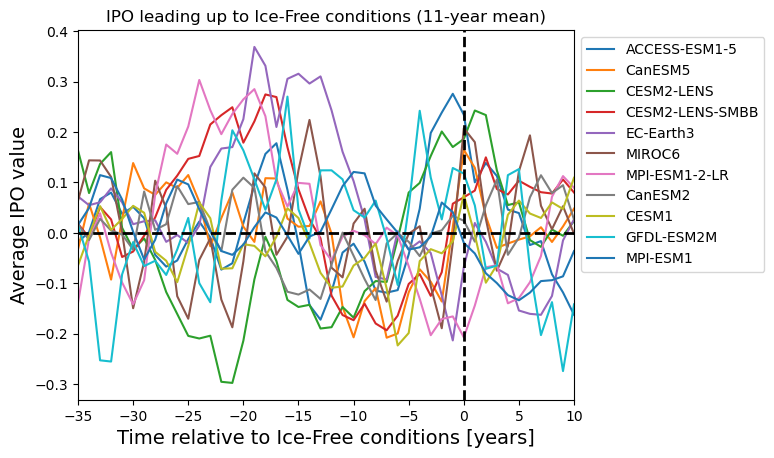

In [114]:
for model_name in model_names:

    #plot the mean of IPO backwards as a line for each model (normalized by SD)
    plt.plot(np.arange(-50,11), IPO_backward[model_name].mean('member'), label=model_name)

plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
plt.axvline(x=0, color='black', linestyle='--', linewidth=2)
plt.xlim(-35,10)
plt.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0)) 
plt.xlabel('Time relative to Ice-Free conditions [years]', fontsize=14)
plt.ylabel('Average IPO value', fontsize=14)
plt.title('IPO leading up to Ice-Free conditions (11-year mean)');

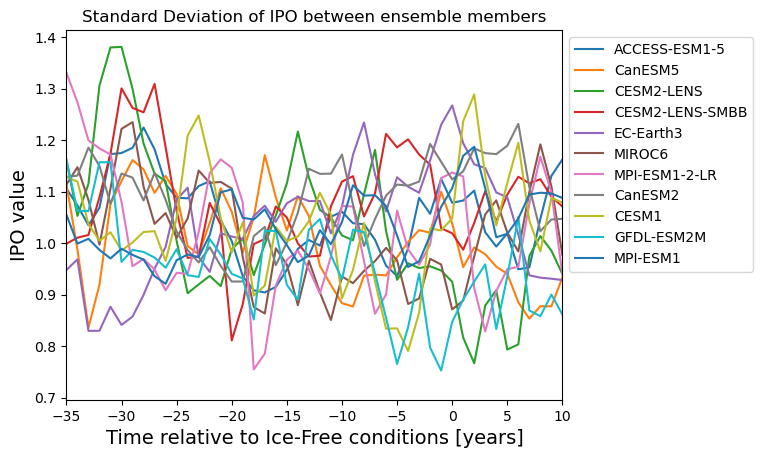

In [125]:
for model_name in model_names:
    plt.plot(np.arange(-50,11), IPO_backward[model_name].std('member'), label=model_name)
    
plt.xlim(-35,10)
plt.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0)) 
plt.xlabel('Time relative to Ice-Free conditions [years]', fontsize=14)
plt.ylabel('IPO value', fontsize=14)
plt.title('Standard Deviation of IPO between ensemble members');
    
    

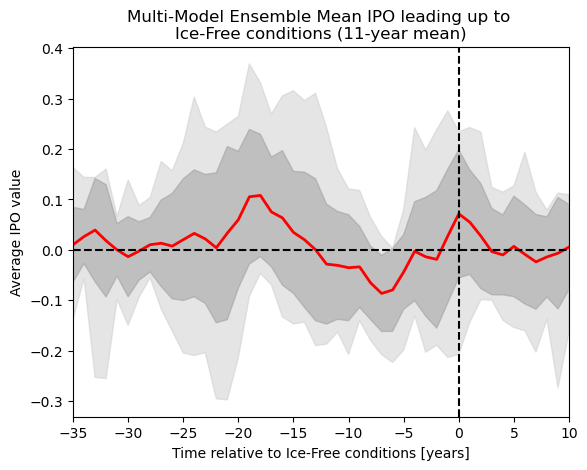

In [124]:
av_model_IPO_backward = []
for model_name in model_names:

    av_model_IPO_backward.append(IPO_backward[model_name].mean('member'))

av_model_IPO_backward_xr = xr.concat((av_model_IPO_backward),dim='model')

plt.plot(np.arange(-50,11), av_model_IPO_backward_xr.mean('model'), 
         color='red', linewidth=2, label='Multi-model Ensemble Mean')
plt.fill_between(np.arange(-50,11), av_model_IPO_backward_xr.mean('model')-av_model_IPO_backward_xr.std('model'),
                av_model_IPO_backward_xr.mean('model')+av_model_IPO_backward_xr.std('model'),
                color='0.4', alpha=0.5, label='SD between models')
plt.fill_between(np.arange(-50,11), av_model_IPO_backward_xr.min('model'),
                av_model_IPO_backward_xr.max('model'),
                color='0.8', alpha=0.5, label='Min/Max of model means')
plt.axhline(y=0, color='black', linestyle='--', linewidth=1.5)
plt.axvline(x=0, color='black', linestyle='--', linewidth=1.5)
plt.xlim(-35,10)
plt.xlabel('Time relative to Ice-Free conditions [years]')
plt.ylabel('Average IPO value')
plt.title('Multi-Model Ensemble Mean IPO leading up to '+'\n'+'Ice-Free conditions (11-year mean)');

### Using the first IF year, not running mean

In [13]:
#look at the backward IPO phases from a running 11-year mean IF year
IPO_backward = {}
IPO_backward_binary = {}
for model_name in model_names:
    print(model_name)

    IPO_backward_mems = []
    IPO_backward_binary_mems = []
    
    SIE_model = SIE_sep_GCMs[model_name]
    IPO_model = IPO_models[model_name]

    for mem_ in SIE_model['member']:
        
        try:
            SIE_mem = SIE_model.sel(member=mem_)
            IPO_mem = IPO_model.sel(member=mem_)
        except KeyError:
            print(model_name, str(mem_.values), 'not available for both SIE and IPO')
            continue
            
        #find IF year, append IPO values for 50 years beforehand, reindex to -50 to 0
        IF_yr = int(SIE_mem['year'].where((SIE_mem - 1) < 0).min())
        IPO_backward_tmp = IPO_mem.sel(year=slice(IF_yr-50,IF_yr+10))
        IPO_backward_tmp['year'] = np.arange(-50,11)
               
        IPO_backward_mems.append(IPO_backward_tmp)

        IPO_backward_binary_mems.append(xr.where(IPO_backward_tmp >= 0.9, 1,
            xr.where(IPO_backward_tmp <= -0.9, -1, 0)))

    IPO_backward_mems_xr = xr.concat((IPO_backward_mems),dim='member')
    IPO_backward[model_name] = IPO_backward_mems_xr

    IPO_backward_mems_binary_xr = xr.concat((IPO_backward_binary_mems),dim='member')
    IPO_backward_binary[model_name] = IPO_backward_mems_binary_xr

ACCESS-ESM1-5
CanESM5
CESM2-LENS
CESM2-LENS-SMBB
EC-Earth3
EC-Earth3 r15i1p1f1 not available for both SIE and IPO
EC-Earth3 r11i1p1f1 not available for both SIE and IPO
EC-Earth3 r4i1p1f1 not available for both SIE and IPO
EC-Earth3 r13i1p1f1 not available for both SIE and IPO
EC-Earth3 r1i1p1f1 not available for both SIE and IPO
EC-Earth3 r6i1p1f1 not available for both SIE and IPO
MIROC6
MPI-ESM1-2-LR
CanESM2
CESM1
GFDL-ESM2M
MPI-ESM1


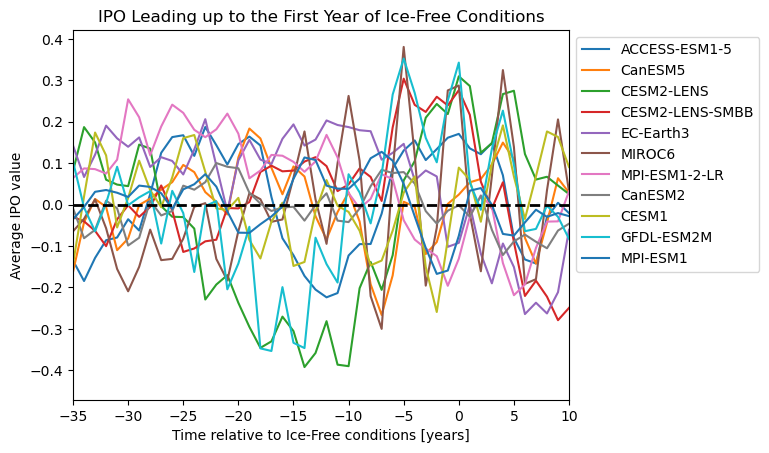

In [133]:
for model_name in model_names:

    #plot the mean of IPO backwards as a line for each model (normalized by SD)
    plt.plot(np.arange(-50,11), IPO_backward[model_name].mean('member'), label=model_name)

plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
plt.xlim(-35,10)
plt.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0)) 
plt.xlabel('Time relative to Ice-Free conditions [years]')
plt.ylabel('Average IPO value')
plt.title('IPO Leading up to the First Year of Ice-Free Conditions');

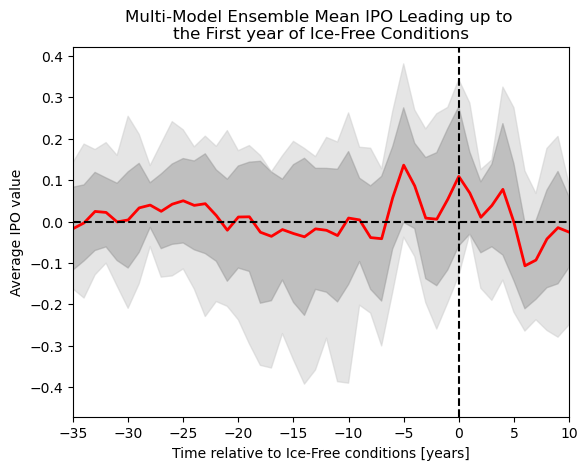

In [134]:
av_model_IPO_backward = []
for model_name in model_names:

    av_model_IPO_backward.append(IPO_backward[model_name].mean('member'))

av_model_IPO_backward_xr = xr.concat((av_model_IPO_backward),dim='model')

plt.plot(np.arange(-50,11), av_model_IPO_backward_xr.mean('model'), 
         color='red', linewidth=2, label='Multi-model Ensemble Mean')
plt.fill_between(np.arange(-50,11), av_model_IPO_backward_xr.mean('model')-av_model_IPO_backward_xr.std('model'),
                av_model_IPO_backward_xr.mean('model')+av_model_IPO_backward_xr.std('model'),
                color='0.4', alpha=0.5, label='SD between models')
plt.fill_between(np.arange(-50,11), av_model_IPO_backward_xr.min('model'),
                av_model_IPO_backward_xr.max('model'),
                color='0.8', alpha=0.5, label='Min/Max of model means')
plt.axhline(y=0, color='black', linestyle='--', linewidth=1.5)
plt.axvline(x=0, color='black', linestyle='--', linewidth=1.5)
plt.xlim(-35,10)
plt.xlabel('Time relative to Ice-Free conditions [years]')
plt.ylabel('Average IPO value')
plt.title('Multi-Model Ensemble Mean IPO Leading up to '+'\n'+'the First year of Ice-Free Conditions');

### Each ensemble member IPO leading up to IF

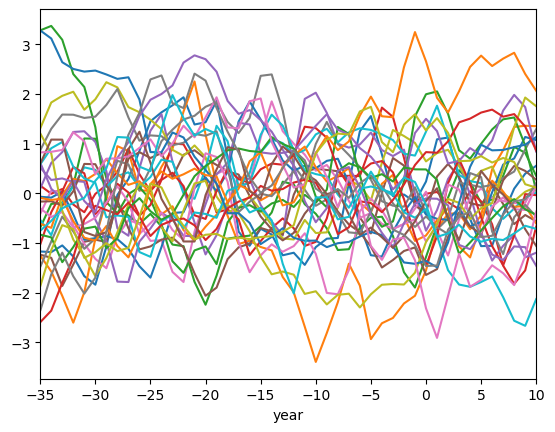

In [35]:
test_model = "MPI-ESM1-2-LR"
IPO_backward[test_model].where(abs(IPO_backward[test_model])>0).plot.line(x='year', add_legend=False, xlim=(-35,10));

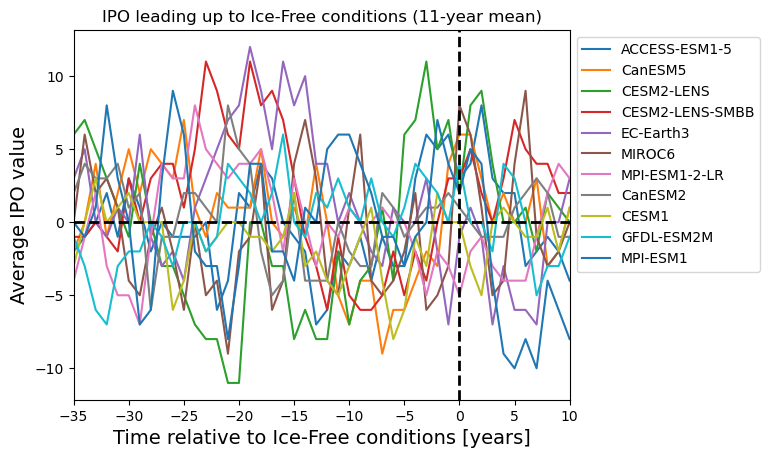

In [89]:
#make binary, then sum up members by phase
sum_threshold = 0.7
for model_name in model_names:

    pos_mems = xr.where(IPO_backward[model_name]>sum_threshold,x=1,y=0)
    neg_mems = xr.where(IPO_backward[model_name]<-sum_threshold,x=-1,y=0)
    mem_sum = (pos_mems + neg_mems).sum('member')

    #plot the mean of IPO backwards as a line for each model (normalized by SD)
    plt.plot(np.arange(-50,11), mem_sum, label=model_name)

plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
plt.axvline(x=0, color='black', linestyle='--', linewidth=2)
plt.xlim(-35,10)
plt.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0)) 
plt.xlabel('Time relative to Ice-Free conditions [years]', fontsize=14)
plt.ylabel('Average IPO value', fontsize=14)
plt.title('IPO leading up to Ice-Free conditions (11-year mean)');

### IPO at 20-15 years before member IF vs 10-5 years before

In [67]:
for model_name in model_names:
    print(model_name+" :"+str((IPO_backward[model_name].sel(year=slice(-10,-5)).mean('year') - IPO_backward[model_name].sel(year=slice(-20,-15)).mean('year')).mean('member').values)
         +"  "+str((IPO_backward[model_name].sel(year=slice(-10,-5)).mean('year') - IPO_backward[model_name].sel(year=slice(-20,-15)).mean('year')).std('member').values))

ACCESS-ESM1-5 :-0.16344216  1.1888401508331299
CanESM5 :-0.20498809  1.19633948802948
CESM2-LENS :0.040213227  1.2952274084091187
CESM2-LENS-SMBB :-0.35905266  1.3551249504089355
EC-Earth3 :-0.3064915  1.2141693830490112
MIROC6 :-0.07122488  1.1016950607299805
MPI-ESM1-2-LR :-0.1866702  0.9911689162254333
CanESM2 :-0.027108038  1.1305947303771973
CESM1 :-0.10742609  0.930820643901825
GFDL-ESM2M :-0.110517375  1.0803570747375488
MPI-ESM1 :0.04581536  1.2521857023239136


## Group the IF years (11-year mean) by time from ensemble mean and plot IPO at different lead times

In [11]:
#use backward IPO phases and also get the IF years
IF_rel_yrs = {}
IF_rel_mean_yrs = {}

for model_name in model_names:
    print(model_name)

    IF_rel_yrs_mems = []
    SIE_model = SIE_sep_GCMs[model_name]

    IF_rel_mean_yrs_mems = []
    SIE_model_mean = sep_SIE_11yr[model_name]

    #find the ensemble mean IF year
    SIE_ens = SIE_model.mean('member')
    IF_yr_ens = int(SIE_ens['year'].where((SIE_ens - 1) < 0).min())

    SIE_mean_ens = SIE_model_mean.mean('member')
    IF_yr_mean_ens = int(SIE_mean_ens['year'].where((SIE_mean_ens - 1) < 0).min())

    for mem_ in SIE_model['member']:
        
        SIE_mem = SIE_model.sel(member=mem_)
        SIE_mean_mem = SIE_model_mean.sel(member=mem_)
        
        #find IF year for individual member
        IF_yr = int(SIE_mem['year'].where((SIE_mem - 1) < 0).min())
        IF_mean_yr = int(SIE_mean_mem['year'].where((SIE_mean_mem - 1) < 0).min())
               
        IF_rel_yrs_mems.append(IF_yr - IF_yr_ens)
        IF_rel_mean_yrs_mems.append(IF_mean_yr - IF_yr_mean_ens)

    IF_rel_yrs_mems_xr = xr.DataArray(data=IF_rel_yrs_mems,dims='member',coords={'member':SIE_model['member']})
    IF_rel_yrs[model_name] = IF_rel_yrs_mems_xr

    IF_rel_yrs_mems_xr = xr.DataArray(data=IF_rel_mean_yrs_mems,dims='member',coords={'member':SIE_model['member']})
    IF_rel_mean_yrs[model_name] = IF_rel_yrs_mems_xr

ACCESS-ESM1-5
CanESM5
CESM2-LENS
CESM2-LENS-SMBB
EC-Earth3
MIROC6
MPI-ESM1-2-LR
CanESM2
CESM1
GFDL-ESM2M
MPI-ESM1


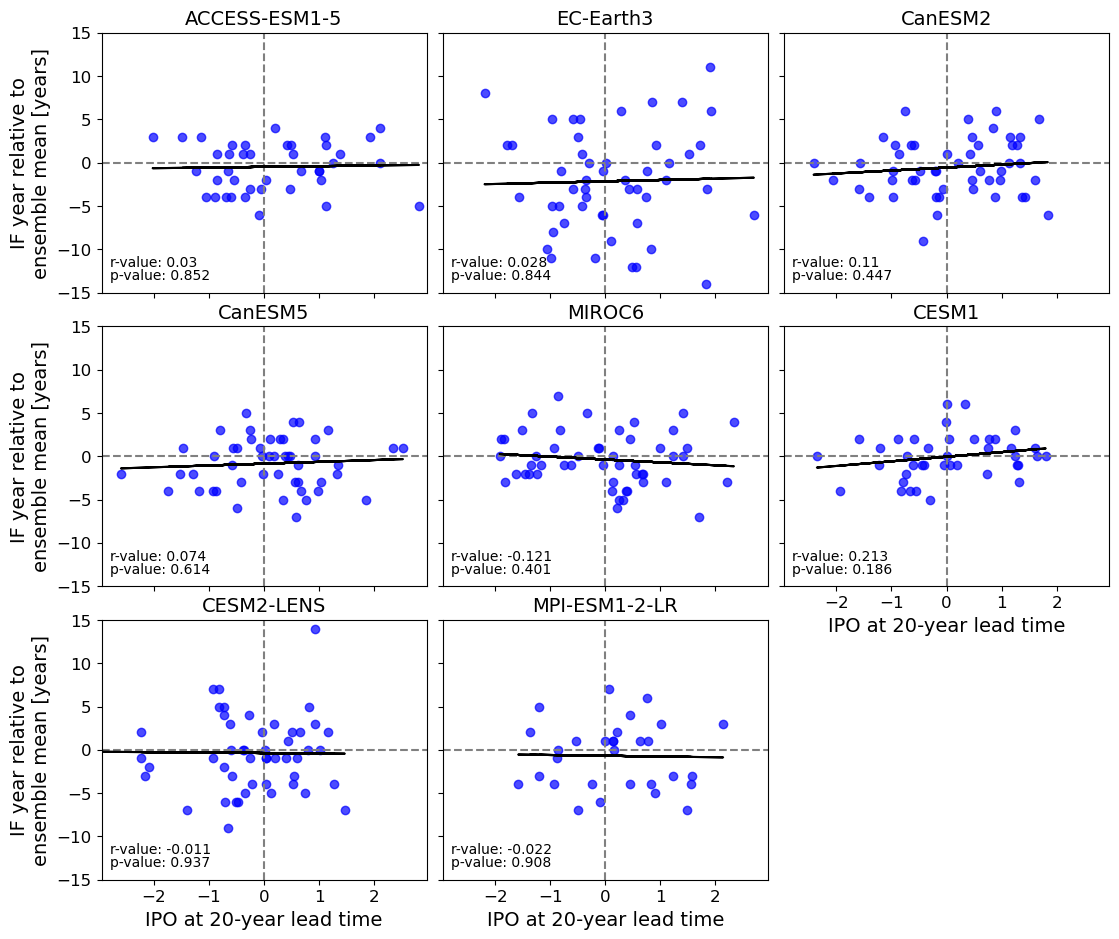

In [16]:
yrs = 20
fig, ax = plt.subplots(3,3,figsize=[13,11])
IPO_data = IPO_backward_mean.copy()#IPO_backward.copy()
IF_rel_data = IF_rel_mean_yrs#IF_rel_yrs

for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):
    
    ax_x = int(model_i%3)
    ax_y = int(np.floor(model_i/3))

    x_vals = IPO_data[model_name].sel(year=-1*yrs)
    y_vals = IF_rel_data[model_name]

    y_vals = y_vals.sel(member=x_vals['member'])
    
    ax[ax_x][ax_y].scatter(
        x_vals, y_vals, color='blue', facecolor=None, alpha=0.7)            
            
    ax[ax_x][ax_y].set_ylim(-15,15)
    ax[ax_x][ax_y].set_xlim(-2.95,2.95)        
            
    ax[ax_x][ax_y].axhline(0, c='0.5',linestyle='--')
    ax[ax_x][ax_y].axvline(0, c='0.5',linestyle='--')
    ax[ax_x][ax_y].set_title(model_name, fontsize=16);
        
    # ax[ax_x][ax_y].set_xticks([-2,-1,0,1,2], fontsize=14)
    # ax[ax_x][ax_y].set_yticks([-15,-10,-5,0,5,10,15], fontsize=14)
    
    if model_i < 3:
        # ax[ax_x][ax_y].set_yticklabels([-0.5,-0.25,0,0.25,0.5], fontsize=13)
        ax[ax_x][ax_y].set_ylabel('IF year relative to'+'\n'+'ensemble mean [years]', fontsize=14)
    else:
        ax[ax_x][ax_y].set_yticklabels([])
    
    if model_i in [2,5,7]:
        ax[ax_x][ax_y].set_xlabel('IPO at '+str(yrs)+'-year lead time', fontsize=14)
        # ax[ax_x][ax_y].set_xticklabels([-0.5,-0.25,0,0.25,0.5], fontsize=13)
    else:
        ax[ax_x][ax_y].set_xlabel([])
        ax[ax_x][ax_y].set_xticklabels([])
        ax[ax_x][ax_y].xaxis.label.set_color('1')
        
    res = stats.linregress(np.ravel(x_vals),np.ravel(y_vals))    
    ax[ax_x][ax_y].plot(np.ravel(x_vals), 
                        res.intercept + res.slope*np.ravel(x_vals), color='k')
    ax[ax_x][ax_y].text(-2.8,-12,'r-value: '+str(np.round(res.rvalue,3)))
    
    #calculate the p-value based on members being the degrees of freedom
    # df = len(IPO_data[model_name]['member'])
    # t_value = ((res.rvalue)*(df-2)**0.5)/(1-(res.rvalue)**2)**0.5
    # p_val = stats.t.sf(np.abs(t_value),df)
    # ax[ax_x][ax_y].text(-2.8,-13.5,'p-value: '+str(np.round(p_val,5)))
    ax[ax_x][ax_y].text(-2.8,-13.5,'p-value: '+str(np.round(res.pvalue,3)))
    
    ax[ax_x][ax_y].set_title(model_name, fontsize=14)
    ax[ax_x][ax_y].tick_params(axis='both', which='major', labelsize=12)
    
ax[2][2].remove()
plt.subplots_adjust(wspace=0.05, hspace=0.13)
plt.savefig('/glade/work/cwpowell/ice-free/figures/IF_11yr_IPO_cor_20yr.pdf',
            bbox_inches='tight')

In [60]:
len(IPO_backward[model_name]['member'])

40

In [64]:
y_vals


<xarray.DataArray (member: 40)>
array([ 2,  1, -4,  0,  2,  2,  0,  6,  1, -2,  1,  2,  0, -1,  4, -1, -4,
       -5, -4, -3,  0, -1, -4, -1,  2, -1, -1,  0, -1,  3,  1, -3, -1,  6,
        2,  1, -1,  0,  2, -2])
Coordinates:
  * member   (member) <U7 'r7i1p1' 'r28i1p1' 'r24i1p1' ... 'r35i1p1' 'r3i1p1'
    year     int64 -45

In [95]:
yr_range = np.arange(0,46)
r_val_dict = {}
p_val_dict = {}
r_val_mean_dict = {}
p_val_mean_dict = {}
r_critical_dict = {}
for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):

    model_r = []
    model_p = []
    model_mean_r = []
    model_mean_p = []
    
    for yrs in yr_range:
        x_vals = IPO_backward[model_name].sel(year=-1*yrs) #IPO at year x from member IF
        y_vals = IF_rel_yrs[model_name] #IF year relative to ensemble mean
        y_vals = y_vals.sel(member=x_vals['member'])
        
        res = stats.linregress(np.ravel(x_vals),np.ravel(y_vals))    
        model_r.append(res.rvalue)
        model_p.append(res.pvalue)
        
        #calculate the p-value based on members being the degrees of freedom
        # df = len(IPO_backward[model_name]['member'])
        # dof = df - 2  # degrees of freedom for the t-distribution
        # t_value = ((res.rvalue)*(dof-2)**0.5)/(1-(res.rvalue)**2)**0.5
        # model_p.append(2 * stats.t.sf(np.abs(t_value),dof)) # x2 as two-tailed

        #do the same for the ensemble mean definition
        x_vals = IPO_backward_mean[model_name].sel(year=-1*yrs) #IPO at year x from ensemble IF
        y_vals = IF_rel_mean_yrs[model_name] #IF year relative to ensemble mean
        y_vals = y_vals.sel(member=x_vals['member'])
        
        res = stats.linregress(np.ravel(x_vals),np.ravel(y_vals))    
        model_mean_r.append(res.rvalue)
        model_mean_p.append(res.pvalue)
        
        #calculate the p-value based on members being the degrees of freedom
        # df = len(IPO_backward_mean[model_name]['member'])
        # dof = df - 2  # degrees of freedom for the t-distribution
        # t_value = ((res.rvalue)*(dof)**0.5)/(1-(res.rvalue)**2)**0.5
        # model_mean_p.append(2 * stats.t.sf(np.abs(t_value),dof)) # x2 as two-tailed

    #calculate the critical r value for this model
    df = len(IPO_backward_mean[model_name]['member'])
    dof = df - 2  # degrees of freedom for the t-distribution
    critical_t = stats.t.ppf(0.025, dof)
    r_critical_dict[model_name] = np.sqrt((critical_t**2) / ((critical_t**2) + dof))

    r_val_dict[model_name] = model_r
    p_val_dict[model_name] = model_p

    r_val_mean_dict[model_name] = model_mean_r
    p_val_mean_dict[model_name] = model_mean_p

In [67]:
#look up lead time with greatest correlation >10 years
max_rval = {}
for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):

    max_rval[model_name] = np.arange(12,46)[np.argmax(np.abs(r_val_mean_dict[model_name][12:]))]

In [68]:
max_rval

{'ACCESS-ESM1-5': 29,
 'CanESM5': 13,
 'CESM2-LENS': 19,
 'EC-Earth3': 45,
 'MIROC6': 20,
 'MPI-ESM1-2-LR': 29,
 'CanESM2': 20,
 'CESM1': 19}

In [69]:
ens_IF = {}
for model_name in ['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']:
    start_yr_LE = int(sep_SIE_11yr[model_name]['year'].where(
                    (sep_SIE_11yr[model_name].mean('member') - 4.7) < 0).min('year'))
    end_yr_LE = int(sep_SIE_11yr[model_name]['year'].where(
                    (sep_SIE_11yr[model_name].mean('member') - 1) < 0).min('year'))
    ens_IF[model_name] = end_yr_LE - start_yr_LE

In [70]:
ens_IF

{'ACCESS-ESM1-5': 35,
 'CanESM5': 25,
 'CESM2-LENS': 43,
 'EC-Earth3': 25,
 'MIROC6': 34,
 'MPI-ESM1-2-LR': 35,
 'CanESM2': 41,
 'CESM1': 27}

In [105]:
#compute the false discovery rate too
from statsmodels.stats.multitest import multipletests

def bh_fdr(p_values, alpha=0.05):
    """
    Standard Benjamini-Hochberg FDR procedure.
    Returns boolean mask of significant tests and the BH-adjusted p-values.
    """
    reject, p_adjusted, _, _ = multipletests(p_values, alpha=alpha, method='fdr_bh')
    return reject, p_adjusted

def wilks_fdr(p_values, alpha=0.05, correlated=True):
    """
    Wilks (2006) FDR approach for correlated (e.g. autocorrelated lag) tests.
    If correlated=True, uses alpha_fdr = 2*alpha as recommended by Wilks
    for serially correlated fields.
    """
    alpha_fdr = 2 * alpha if correlated else alpha
    reject, p_adjusted = bh_fdr(p_values, alpha=alpha_fdr)
    return reject, p_adjusted, alpha_fdr

# --- Example usage ---
# p_values: array of 46 p-values from your lag correlations
for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):

    print(model_name)
    
    p_values = p_val_mean_dict[model_name]  # your 46 p-values here
    
    reject_std, p_adj_std = bh_fdr(p_values, alpha=0.05)
    reject_wilks, p_adj_wilks, alpha_used = wilks_fdr(p_values, alpha=0.05, correlated=True)
    
    print(f"Number of p values <0.05: {len(np.ravel(np.where(np.array(p_values)<0.05)))} exceed critical r value")
    print(f"Standard BH-FDR: {reject_std.sum()} of {len(p_values)} lags significant")
    print(f"Wilks FDR (alpha_fdr={alpha_used}): {reject_wilks.sum()} of {len(p_values)} lags significant")
    
    # See which specific lags survive
    sig_lags_BH = np.where(reject_std)[0]
    print("Significant lag indices (BH):", sig_lags_BH)
    sig_lags_wilks = np.where(reject_wilks)[0]
    print("Significant lag indices (Wilks):", sig_lags_wilks)

ACCESS-ESM1-5
Number of p values <0.05: 1 exceed critical r value
Standard BH-FDR: 0 of 46 lags significant
Wilks FDR (alpha_fdr=0.1): 0 of 46 lags significant
Significant lag indices (BH): []
Significant lag indices (Wilks): []
CanESM5
Number of p values <0.05: 0 exceed critical r value
Standard BH-FDR: 0 of 46 lags significant
Wilks FDR (alpha_fdr=0.1): 0 of 46 lags significant
Significant lag indices (BH): []
Significant lag indices (Wilks): []
CESM2-LENS
Number of p values <0.05: 0 exceed critical r value
Standard BH-FDR: 0 of 46 lags significant
Wilks FDR (alpha_fdr=0.1): 0 of 46 lags significant
Significant lag indices (BH): []
Significant lag indices (Wilks): []
EC-Earth3
Number of p values <0.05: 15 exceed critical r value
Standard BH-FDR: 0 of 46 lags significant
Wilks FDR (alpha_fdr=0.1): 0 of 46 lags significant
Significant lag indices (BH): []
Significant lag indices (Wilks): []
MIROC6
Number of p values <0.05: 4 exceed critical r value
Standard BH-FDR: 0 of 46 lags signifi

In [116]:
[r_val_mean_dict[model_name][i] for i in (11,18,19)]

[0.5065999320236465, 0.4753663731767796, 0.5057992827597148]

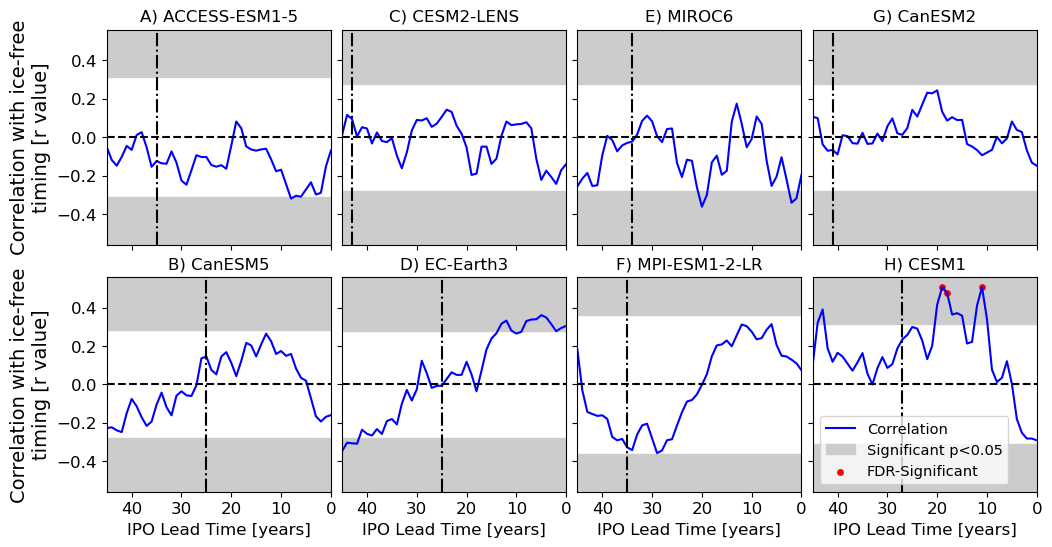

In [137]:
letter_list = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']

fig, ax = plt.subplots(2,4,figsize=[12,6])

for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):
    
    ax_x = int(model_i%2)
    ax_y = int(np.floor(model_i/2))

    # ax[ax_x][ax_y].plot(yr_range, r_val_dict[model_name],color='r', label='First Ice-Free Year')     
    ax[ax_x][ax_y].plot(yr_range, r_val_mean_dict[model_name],color='b', label='Correlation')     
    
    #now, instead shade in gray where significant 
    ax[ax_x][ax_y].fill_between(
        [-50,50],[r_critical_dict[model_name],r_critical_dict[model_name]],[9,9],color='0.8', label='Significant p<0.05')
    ax[ax_x][ax_y].fill_between(
        [-50,50],[-1*r_critical_dict[model_name],-1*r_critical_dict[model_name]],[-9,-9],color='0.8')
            
    ax[ax_x][ax_y].set_ylim(-0.56,0.56)
    ax[ax_x][ax_y].set_xlim(1,45)        
            
    ax[ax_x][ax_y].axhline(0, c='k',linestyle='--')
    ax[ax_x][ax_y].axvline(ens_IF[model_name], c='k',linestyle='-.')
    ax[ax_x][ax_y].set_title(model_name, fontsize=16);

    #plot the points that pass the Benjamini-Hochberg FDR for CESM1
    if model_name == 'CESM1':
        ax[ax_x][ax_y].scatter([yr_range[i] for i in (11,18,19)], 
                               [r_val_mean_dict[model_name][i] for i in (11,18,19)], 
                               c='r', s=15, label='FDR-Significant')
    
    if model_i < 2:
        ax[ax_x][ax_y].set_ylabel('Correlation with ice-free'+'\n'+'timing [r value]', fontsize=14)
    else:
        ax[ax_x][ax_y].set_yticklabels([])
    
    if model_i in [1,3,5,7]:
        ax[ax_x][ax_y].set_xlabel('IPO Lead Time [years]', fontsize=12)
        ax[ax_x][ax_y].set_xticks([40,30,20,10,0])
    else:
        ax[ax_x][ax_y].set_xlabel([])
        ax[ax_x][ax_y].set_xticks([40,30,20,10,0])
        ax[ax_x][ax_y].set_xticklabels([])
        ax[ax_x][ax_y].xaxis.label.set_color('1')
    
    ax[ax_x][ax_y].set_title(letter_list[model_i]+') '+model_name, fontsize=12)
    ax[ax_x][ax_y].invert_xaxis()
    ax[ax_x][ax_y].tick_params(axis='both', which='major', labelsize=12)


plt.subplots_adjust(wspace=0.05, hspace=0.15)

#add legend
ax[1][3].legend(fontsize=10.5);
                    
plt.savefig('/glade/work/cwpowell/ice-free/figures/Correlation_IF_IPO_with_FDR.pdf',
            bbox_inches='tight')

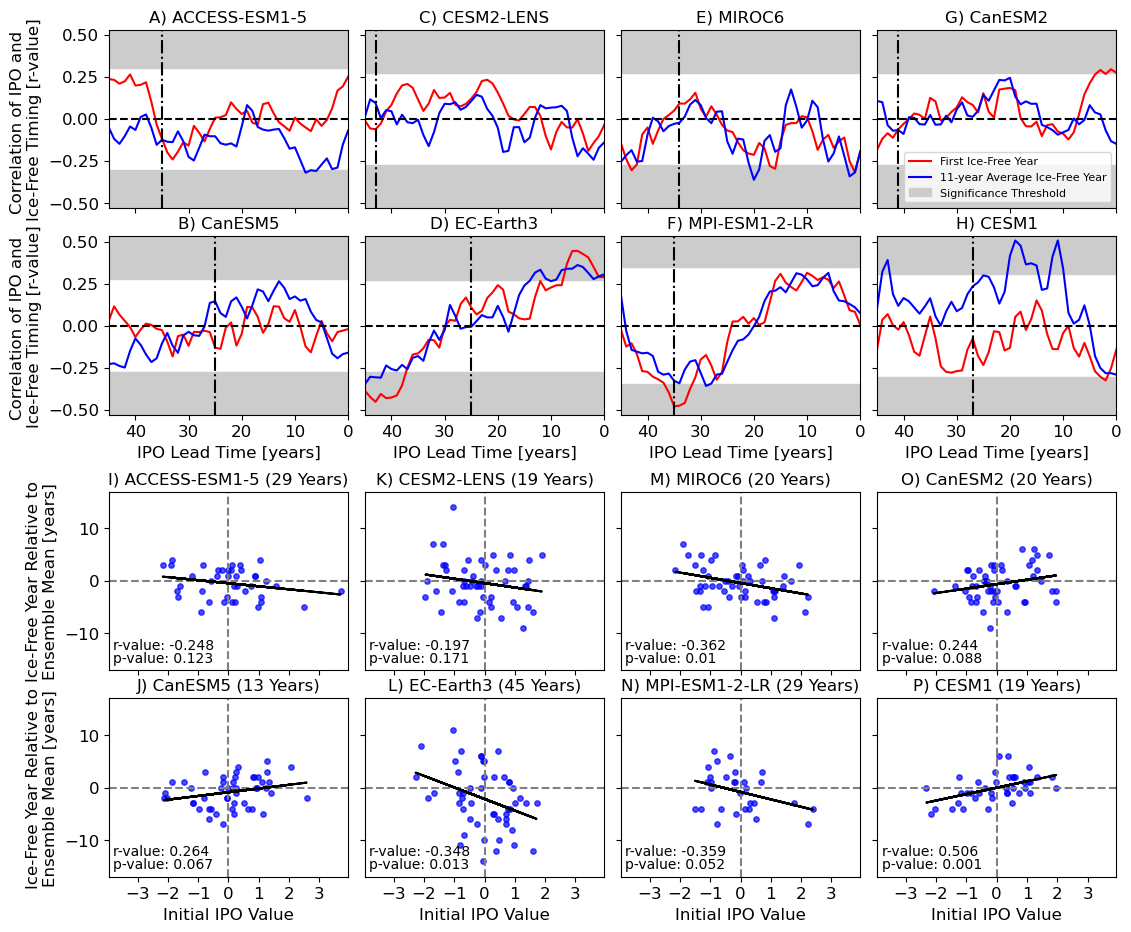

In [140]:
# Create a figure with two main vertical groups (top 2 rows, bottom 2 rows)
letter_list = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']
fig = plt.figure(figsize=[13, 11])
outer_gs = gridspec.GridSpec(2, 1, hspace=0.2) # Increase this hspace for the middle gap

# Sub-grid for the top two rows (Plots 1-8)
gs_top = outer_gs[0].subgridspec(2, 4, wspace=0.07, hspace=0.16)
# Sub-grid for the bottom two rows (Scatter plots)
gs_bottom = outer_gs[1].subgridspec(2, 4, wspace=0.07, hspace=0.16)

# Then add axes using these gridspecs instead of plt.subplots(4,4)
ax = [[None for _ in range(4)] for _ in range(4)]
for r in range(2):
    for c in range(4):
        ax[r][c] = fig.add_subplot(gs_top[r, c])
        ax[r+2][c] = fig.add_subplot(gs_bottom[r, c])

# fig, ax = plt.subplots(4,4,figsize=[13,11])
for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):
    
    ax_x = int(model_i%2)
    ax_y = int(np.floor(model_i/2))

    ax[ax_x][ax_y].plot(yr_range, r_val_dict[model_name],color='r', label='First Ice-Free Year')     
    ax[ax_x][ax_y].plot(yr_range, r_val_mean_dict[model_name],color='b', label='11-year Average Ice-Free Year')     
    
    #now, instead shade in gray where significant 
    ax[ax_x][ax_y].fill_between(
        [-50,50],[r_critical_dict[model_name],r_critical_dict[model_name]],[9,9],color='0.8', label='Significance Threshold')
    ax[ax_x][ax_y].fill_between(
        [-50,50],[-1*r_critical_dict[model_name],-1*r_critical_dict[model_name]],[-9,-9],color='0.8')
            
    ax[ax_x][ax_y].set_ylim(-0.53,0.53)
    ax[ax_x][ax_y].set_xlim(0,45)        
            
    ax[ax_x][ax_y].axhline(0, c='k',linestyle='--')
    ax[ax_x][ax_y].axvline(ens_IF[model_name], c='k',linestyle='-.')
    ax[ax_x][ax_y].set_title(model_name, fontsize=16);
    
    if model_i in [0,1]:
        ax[ax_x][ax_y].set_ylabel('Correlation of IPO and '+'\n'+'Ice-Free Timing [r-value]', fontsize=12)
    else:
        ax[ax_x][ax_y].set_yticklabels([])
    
    if model_i in [1,3,5,7]:
        ax[ax_x][ax_y].set_xlabel('IPO Lead Time [years]', fontsize=12)
        ax[ax_x][ax_y].set_xticks([40,30,20,10,0])
    else:
        ax[ax_x][ax_y].set_xlabel([])
        ax[ax_x][ax_y].set_xticks([40,30,20,10,0])
        ax[ax_x][ax_y].set_xticklabels([])
        ax[ax_x][ax_y].xaxis.label.set_color('1')
    
    ax[ax_x][ax_y].set_title(letter_list[model_i]+') '+model_name, fontsize=12)
    ax[ax_x][ax_y].invert_xaxis()
    ax[ax_x][ax_y].tick_params(axis='both', which='major', labelsize=12)
    
#add legend
ax[0][3].legend(fontsize=8)#, bbox_to_anchor=(0.5,0.15))

IPO_data = IPO_backward_mean.copy()#IPO_backward.copy()
IF_rel_data = IF_rel_mean_yrs#IF_rel_yrs

for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):
    
    ax_x = int(model_i%2)+2
    ax_y = int(np.floor(model_i/2))

    x_vals = IPO_data[model_name].sel(year=-1*max_rval[model_name])
    y_vals = IF_rel_data[model_name]

    y_vals = y_vals.sel(member=x_vals['member'])
    
    ax[ax_x][ax_y].scatter(
        x_vals, y_vals, color='blue', s=15, facecolor=None, alpha=0.7)            
            
    ax[ax_x][ax_y].set_ylim(-17,17)
    ax[ax_x][ax_y].set_xlim(-3.95,3.95)        
            
    ax[ax_x][ax_y].axhline(0, c='0.5',linestyle='--')
    ax[ax_x][ax_y].axvline(0, c='0.5',linestyle='--')
    
    if model_i in [0,1]:
        ax[ax_x][ax_y].set_ylabel('Ice-Free Year Relative to'+'\n'+'Ensemble Mean [years]', fontsize=12)
    else:
        ax[ax_x][ax_y].set_yticklabels([])
    
    if model_i in [1,3,5,7]:
        ax[ax_x][ax_y].set_xlabel('Initial IPO Value', fontsize=12)
        ax[ax_x][ax_y].set_xticks([-3,-2,-1,0,1,2,3])
    else:
        ax[ax_x][ax_y].set_xlabel([])
        ax[ax_x][ax_y].set_xticks([-3,-2,-1,0,1,2,3])
        ax[ax_x][ax_y].set_xticklabels([])
        ax[ax_x][ax_y].xaxis.label.set_color('1')
        
    res = stats.linregress(np.ravel(x_vals),np.ravel(y_vals))    
    ax[ax_x][ax_y].plot(np.ravel(x_vals), 
                        res.intercept + res.slope*np.ravel(x_vals), color='k')
    ax[ax_x][ax_y].text(-3.8,-13,'r-value: '+str(np.round(res.rvalue,3)))
    ax[ax_x][ax_y].text(-3.8,-15.5,'p-value: '+str(np.round(res.pvalue,3)))
    
    ax[ax_x][ax_y].set_title(letter_list[model_i+8]+') '+model_name+' ('+str(max_rval[model_name])+' Years)', fontsize=12)
    ax[ax_x][ax_y].tick_params(axis='both', which='major', labelsize=12);
    
                    
plt.savefig('/glade/work/cwpowell/ice-free/figures/Correlation_IF_IPO_0_to_46_years_plus_peak_cor_letters.pdf',
            bbox_inches='tight')

## Look at IPO effect by mean state

In [91]:
#need to recalculate everything based on trajectories of 4.2-5.2 SIE in increments of 0.1 million sq km
IPO_pos_dict = {}
IPO_neg_dict = {}
ens_sd_dict = {}
ens_end_dict = {}

# IPO_phase_th = 0.9
n_years_fut = 20

for model_name in ['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']:
    print(model_name)
    
    IPO_pos_ = []
    IPO_neg_ = []
    ens_sd_ = []
    ens_all_ = []

    for start_SIE in np.arange(1,6.1,0.1):

        #find year to start with of ensemble mean 
        ens_mean = sep_SIE_11yr[model_name].mean('member')
        ens_mean_yr = sep_SIE_11yr[model_name]['year'].where(
                (ens_mean - start_SIE) < 0).min('year')
        ens_end_.append(ens_mean.sel(year=ens_mean_yr+n_years_fut))
        
        IPO_pos_mem = []
        IPO_neg_mem = []
        ens_sd_mem = []
        
        for mem_ in IPO_models[model_name]['member']:
            if mem_ == 'r49i1p1':
                continue
            
            #find latest matching year to selected SIE, define start_year
            # start_yr_mem = int(sep_SIE_11yr[model_name]['year'].where(
            #     (sep_SIE_11yr[model_name].sel(member=mem_) - start_SIE) < 0).min('year'))

            #always append the SIE with years corrected to 0-51
            mem_SIE_final = sep_SIE_11yr[model_name].sel(member=mem_).sel(
                year=ens_mean_yr+n_years_fut) - ens_mean.sel(
                year=ens_mean_yr+n_years_fut)
            
            ###### persistence metric of 10+ years in same phase
            # IPO_pos = (IPO_models[model_name].sel(member=mem_).sel(
            #     year=slice(start_yr_mem-9,start_yr_mem))>0).min('year')==True
            # IPO_neg = (IPO_models[model_name].sel(member=mem_).sel(
            #     year=slice(start_yr_mem-9,start_yr_mem))<0).min('year')==True
            
            ###### S&D method of +/- 0.9
            IPO_pos = IPO_models[model_name].sel(member=mem_).sel(year=start_yr_mem)>0.9
            IPO_neg = IPO_models[model_name].sel(member=mem_).sel(year=start_yr_mem)<-0.9
            
            if IPO_pos:
                IPO_pos_mem.append(mem_SIE_final)
            elif IPO_neg:
                IPO_neg_mem.append(mem_SIE_final)
            ens_sd_mem.append(mem_SIE_final)
        
        #also calculate the standard deviation, if at least 2 trajectories        
        IPO_pos_.append(xr.concat((IPO_pos_mem),dim='member').values)
        IPO_neg_.append(xr.concat((IPO_neg_mem),dim='member').values)
        ens_sd_.append(xr.concat((ens_sd_mem),dim='member').std())
    
    IPO_pos_dict[model_name] = IPO_pos_
    IPO_neg_dict[model_name] = IPO_neg_
    ens_sd_dict[model_name] = ens_sd_
    ens_end_dict[model_name] = ens_end_

ACCESS-ESM1-5
CanESM5
CESM2-LENS
EC-Earth3
MIROC6
MPI-ESM1-2-LR
CanESM2
CESM1


/glade/derecho/scratch/cwpowell/tmp/ipykernel_30424/2488439823.py:13: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean(), c=[0.25,0.5,1], label='IPO -ve')
/glade/derecho/scratch/cwpowell/tmp/ipykernel_30424/2488439823.py:16: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean(), c=[0.25,0.5,1])


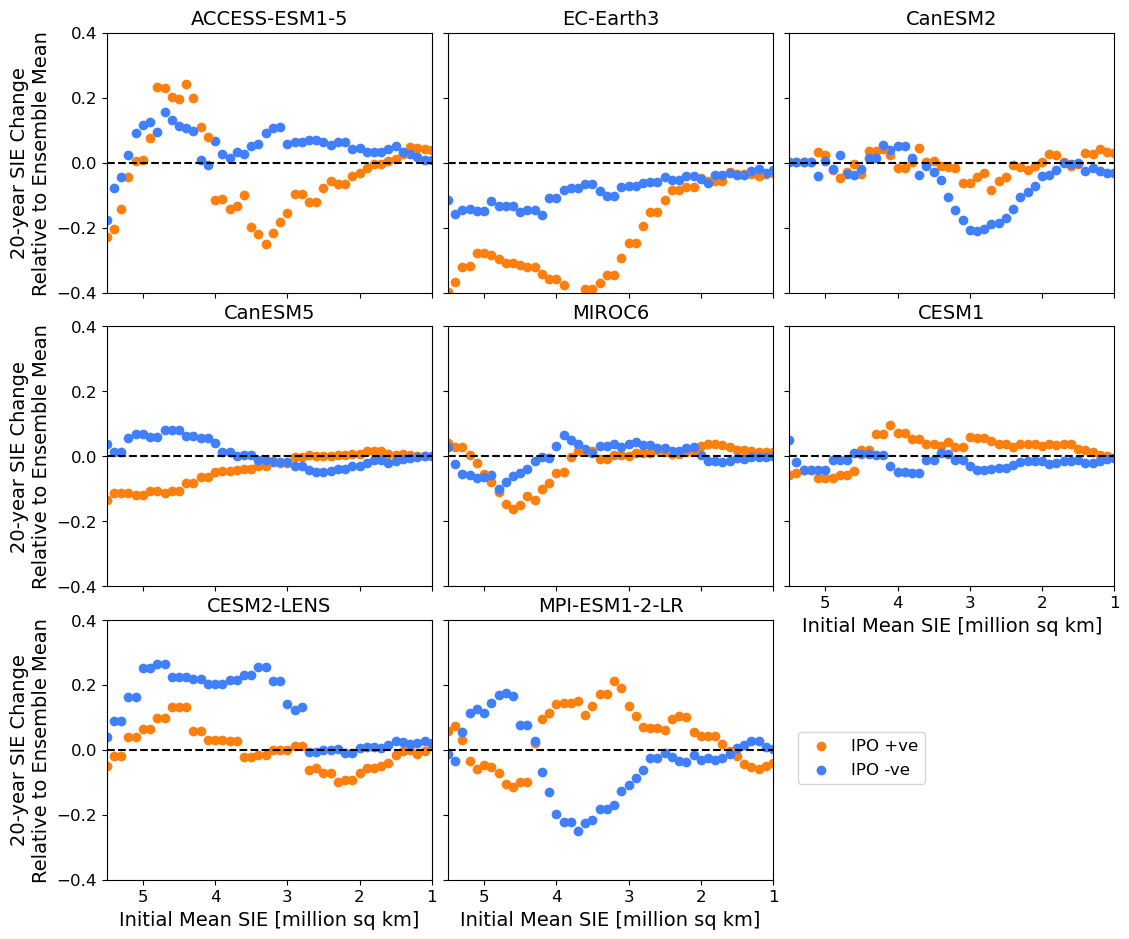

In [83]:
fig, ax = plt.subplots(3,3,figsize=[13,11])

for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):
    
    ax_x = int(model_i%3)
    ax_y = int(np.floor(model_i/3))

    for i,init_SIE in enumerate(np.arange(1,6.1,0.1)):
        if i ==0:
            ax[ax_x][ax_y].scatter(init_SIE, IPO_pos_dict[model_name][i].mean(), c='tab:orange', label='IPO +ve')
            ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean(), c=[0.25,0.5,1], label='IPO -ve')
        else:
            ax[ax_x][ax_y].scatter(init_SIE, IPO_pos_dict[model_name][i].mean(), c='tab:orange')
            ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean(), c=[0.25,0.5,1])
    
    ax[ax_x][ax_y].set_ylim(-0.4,0.4)
    ax[ax_x][ax_y].set_xlim(1,5.5)        
            
    ax[ax_x][ax_y].axhline(0, c='k',linestyle='--')
    ax[ax_x][ax_y].set_title(model_name, fontsize=16);
    
    if model_i < 3:
        ax[ax_x][ax_y].set_ylabel('20-year SIE Change'+'\n'+'Relative to Ensemble Mean', fontsize=14)
    else:
        ax[ax_x][ax_y].set_yticklabels([])
    
    if model_i in [2,5,7]:
        ax[ax_x][ax_y].set_xlabel('Initial Mean SIE [million sq km]', fontsize=14)
    else:
        ax[ax_x][ax_y].set_xlabel([])
        ax[ax_x][ax_y].set_xticklabels([])
        ax[ax_x][ax_y].xaxis.label.set_color('1')
    
    ax[ax_x][ax_y].set_title(model_name, fontsize=14)
    ax[ax_x][ax_y].invert_xaxis()
    ax[ax_x][ax_y].tick_params(axis='both', which='major', labelsize=12)
    
ax[2][2].remove()
plt.subplots_adjust(wspace=0.05, hspace=0.13)

#add legend
plt.legend(fontsize=12, bbox_to_anchor=(1.05,0.6));

/glade/derecho/scratch/cwpowell/tmp/ipykernel_30424/2332379102.py:13: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[ax_x][ax_y].scatter(ens_end_dict[model_name][i], IPO_neg_dict[model_name][i].mean(), c=[0.25,0.5,1], label='IPO -ve')
/glade/derecho/scratch/cwpowell/tmp/ipykernel_30424/2332379102.py:16: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[ax_x][ax_y].scatter(ens_end_dict[model_name][i], IPO_neg_dict[model_name

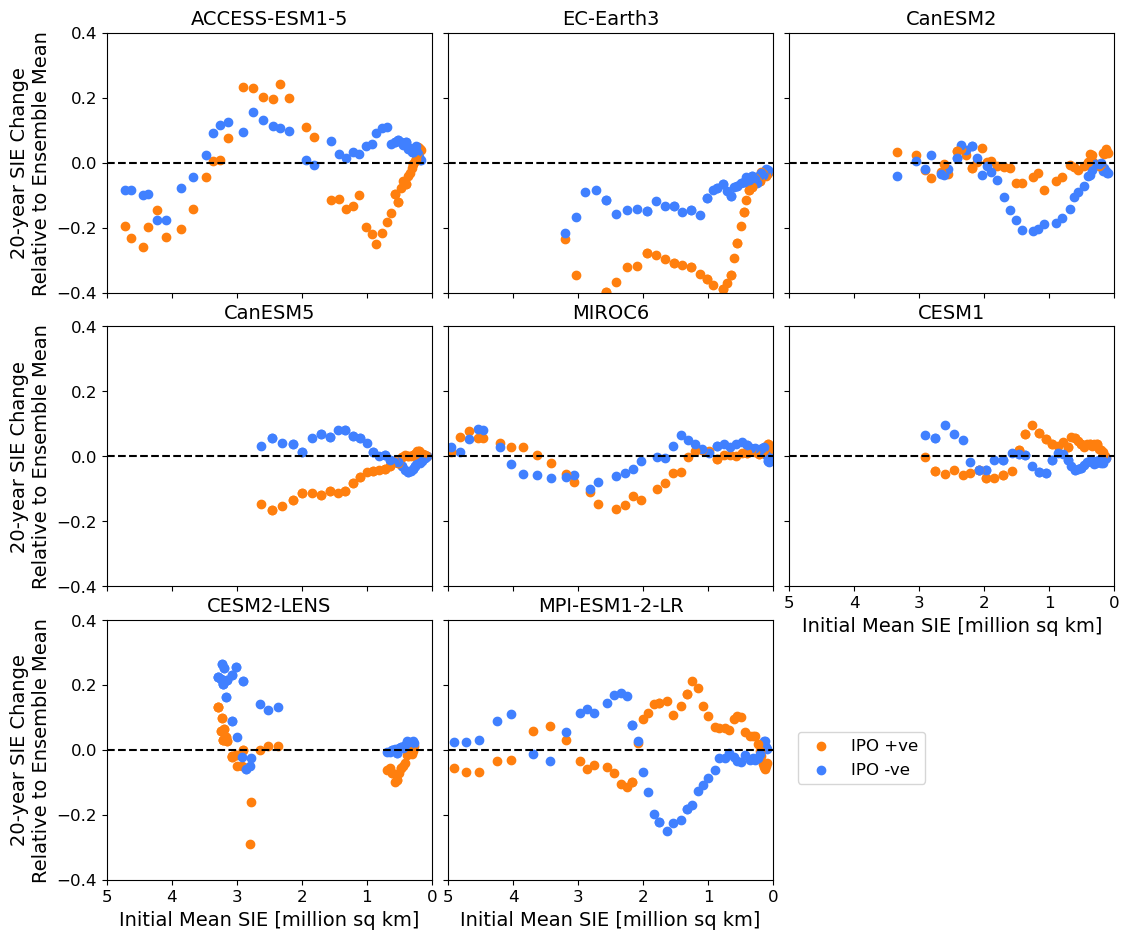

In [88]:
fig, ax = plt.subplots(3,3,figsize=[13,11])

for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):
    
    ax_x = int(model_i%3)
    ax_y = int(np.floor(model_i/3))

    for i,init_SIE in enumerate(np.arange(1,6.1,0.1)):
        if i ==0:
            ax[ax_x][ax_y].scatter(ens_end_dict[model_name][i], IPO_pos_dict[model_name][i].mean(), c='tab:orange', label='IPO +ve')
            ax[ax_x][ax_y].scatter(ens_end_dict[model_name][i], IPO_neg_dict[model_name][i].mean(), c=[0.25,0.5,1], label='IPO -ve')
        else:
            ax[ax_x][ax_y].scatter(ens_end_dict[model_name][i], IPO_pos_dict[model_name][i].mean(), c='tab:orange')
            ax[ax_x][ax_y].scatter(ens_end_dict[model_name][i], IPO_neg_dict[model_name][i].mean(), c=[0.25,0.5,1])
    
    ax[ax_x][ax_y].set_ylim(-0.4,0.4)
    ax[ax_x][ax_y].set_xlim(0,5)        
            
    ax[ax_x][ax_y].axhline(0, c='k',linestyle='--')
    ax[ax_x][ax_y].set_title(model_name, fontsize=16);
    
    if model_i < 3:
        ax[ax_x][ax_y].set_ylabel('20-year SIE Change'+'\n'+'Relative to Ensemble Mean', fontsize=14)
    else:
        ax[ax_x][ax_y].set_yticklabels([])
    
    if model_i in [2,5,7]:
        ax[ax_x][ax_y].set_xlabel('Initial Mean SIE [million sq km]', fontsize=14)
    else:
        ax[ax_x][ax_y].set_xlabel([])
        ax[ax_x][ax_y].set_xticklabels([])
        ax[ax_x][ax_y].xaxis.label.set_color('1')
    
    ax[ax_x][ax_y].set_title(model_name, fontsize=14)
    ax[ax_x][ax_y].invert_xaxis()
    ax[ax_x][ax_y].tick_params(axis='both', which='major', labelsize=12)
    
ax[2][2].remove()
plt.subplots_adjust(wspace=0.05, hspace=0.13)

#add legend
plt.legend(fontsize=12, bbox_to_anchor=(1.05,0.6));

/glade/derecho/scratch/cwpowell/tmp/ipykernel_30424/1265545399.py:14: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c=[0.25,0.5,1], label='IPO -ve')
/glade/derecho/scratch/cwpowell/tmp/ipykernel_30424/1265545399.py:17: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()

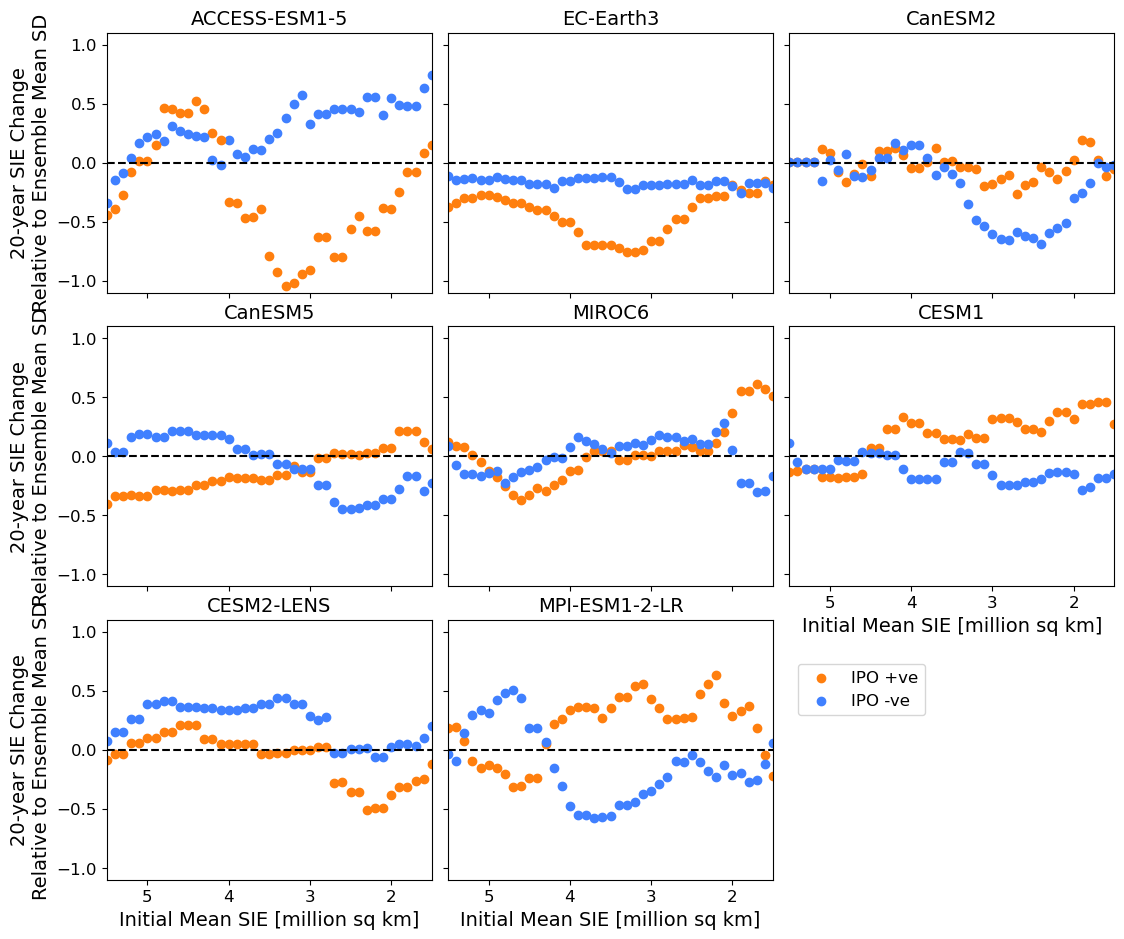

In [97]:
#plot relative to SD from ensemble mean
fig, ax = plt.subplots(3,3,figsize=[13,11])

for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):
    
    ax_x = int(model_i%3)
    ax_y = int(np.floor(model_i/3))

    for i,init_SIE in enumerate(np.arange(1,6.1,0.1)):
        if i ==0:
            ax[ax_x][ax_y].scatter(init_SIE, IPO_pos_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c='tab:orange', label='IPO +ve')
            ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c=[0.25,0.5,1], label='IPO -ve')
        else:
            ax[ax_x][ax_y].scatter(init_SIE, IPO_pos_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c='tab:orange')
            ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c=[0.25,0.5,1])
    
    ax[ax_x][ax_y].set_ylim(-1.1,1.1)
    ax[ax_x][ax_y].set_xlim(1.5,5.5)        
            
    ax[ax_x][ax_y].axhline(0, c='k',linestyle='--')
    ax[ax_x][ax_y].set_title(model_name, fontsize=16);
    
    if model_i < 3:
        ax[ax_x][ax_y].set_ylabel('20-year SIE Change'+'\n'+'Relative to Ensemble Mean SD', fontsize=14)
    else:
        ax[ax_x][ax_y].set_yticklabels([])
    
    if model_i in [2,5,7]:
        ax[ax_x][ax_y].set_xlabel('Initial Mean SIE [million sq km]', fontsize=14)
    else:
        ax[ax_x][ax_y].set_xlabel([])
        ax[ax_x][ax_y].set_xticklabels([])
        ax[ax_x][ax_y].xaxis.label.set_color('1')
    
    ax[ax_x][ax_y].set_title(model_name, fontsize=14)
    ax[ax_x][ax_y].invert_xaxis()
    ax[ax_x][ax_y].tick_params(axis='both', which='major', labelsize=12)
    
ax[2][2].remove()
plt.subplots_adjust(wspace=0.05, hspace=0.13)

#add legend
plt.legend(fontsize=12, bbox_to_anchor=(1.05,0.6));

In [106]:
#need to recalculate everything based on trajectories of 4.2-5.2 SIE in increments of 0.1 million sq km
IPO_pos_dict = {}
IPO_neg_dict = {}
ens_sd_dict = {}
ens_end_dict = {}

# IPO_phase_th = 0.9
n_years_fut = 20

for model_name in ['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']:
    print(model_name)
    
    IPO_pos_ = []
    IPO_neg_ = []
    ens_sd_ = []
    ens_all_ = []

    for start_SIE in np.arange(1,6.1,0.1):

        #find year to start with of ensemble mean 
        ens_mean = sep_SIE_11yr[model_name].mean('member')
        ens_mean_yr = sep_SIE_11yr[model_name]['year'].where(
                (ens_mean - start_SIE) < 0).min('year')
        ens_end_.append(ens_mean.sel(year=ens_mean_yr+n_years_fut))
        
        IPO_pos_mem = []
        IPO_neg_mem = []
        ens_sd_mem = []
        
        for mem_ in IPO_models[model_name]['member']:
            if mem_ == 'r49i1p1':
                continue
            
            #find latest matching year to selected SIE, define start_year
            # start_yr_mem = int(sep_SIE_11yr[model_name]['year'].where(
            #     (sep_SIE_11yr[model_name].sel(member=mem_) - start_SIE) < 0).min('year'))

            #always append the SIE with years corrected to 0-51
            mem_SIE_final = sep_SIE_11yr[model_name].sel(member=mem_).sel(
                year=ens_mean_yr+n_years_fut) - ens_mean.sel(
                year=ens_mean_yr+n_years_fut)
            
            ###### persistence metric of 10+ years in same phase
            IPO_pos = (IPO_models[model_name].sel(member=mem_).sel(
                year=slice(start_yr_mem-9,start_yr_mem))>0).min('year')==True
            IPO_neg = (IPO_models[model_name].sel(member=mem_).sel(
                year=slice(start_yr_mem-9,start_yr_mem))<0).min('year')==True
            
            ###### S&D method of +/- 0.9
            # IPO_pos = IPO_models[model_name].sel(member=mem_).sel(year=start_yr_mem)>0.9
            # IPO_neg = IPO_models[model_name].sel(member=mem_).sel(year=start_yr_mem)<-0.9
            
            if IPO_pos:
                IPO_pos_mem.append(mem_SIE_final)
            elif IPO_neg:
                IPO_neg_mem.append(mem_SIE_final)
            ens_sd_mem.append(mem_SIE_final)
        
        #also calculate the standard deviation, if at least 2 trajectories        
        IPO_pos_.append(xr.concat((IPO_pos_mem),dim='member').values)
        IPO_neg_.append(xr.concat((IPO_neg_mem),dim='member').values)
        ens_sd_.append(xr.concat((ens_sd_mem),dim='member').std())
    
    IPO_pos_dict[model_name] = IPO_pos_
    IPO_neg_dict[model_name] = IPO_neg_
    ens_sd_dict[model_name] = ens_sd_
    ens_end_dict[model_name] = ens_end_

ACCESS-ESM1-5
CanESM5
CESM2-LENS
EC-Earth3
MIROC6
MPI-ESM1-2-LR
CanESM2
CESM1


/glade/derecho/scratch/cwpowell/tmp/ipykernel_30424/1961451792.py:13: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c=[0.25,0.5,1], label='IPO -ve')
/glade/derecho/scratch/cwpowell/tmp/ipykernel_30424/1961451792.py:16: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()

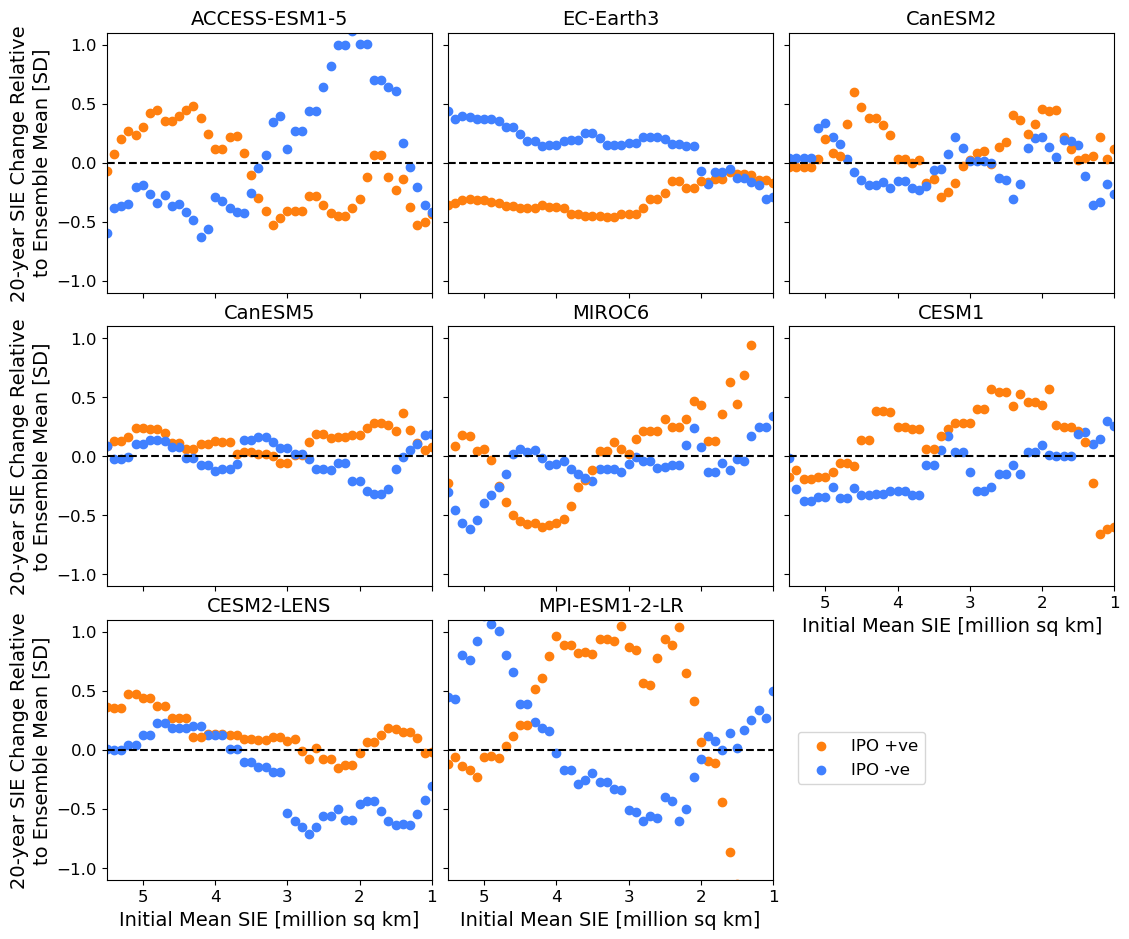

In [107]:
fig, ax = plt.subplots(3,3,figsize=[13,11])

for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):
    
    ax_x = int(model_i%3)
    ax_y = int(np.floor(model_i/3))

    for i,init_SIE in enumerate(np.arange(1,6.1,0.1)):
        if i ==0:
            ax[ax_x][ax_y].scatter(init_SIE, IPO_pos_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c='tab:orange', label='IPO +ve')
            ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c=[0.25,0.5,1], label='IPO -ve')
        else:
            ax[ax_x][ax_y].scatter(init_SIE, IPO_pos_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c='tab:orange')
            ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c=[0.25,0.5,1])
    
    ax[ax_x][ax_y].set_ylim(-1.1,1.1)
    ax[ax_x][ax_y].set_xlim(1,5.5)        
            
    ax[ax_x][ax_y].axhline(0, c='k',linestyle='--')
    ax[ax_x][ax_y].set_title(model_name, fontsize=16);
    
    if model_i < 3:
        ax[ax_x][ax_y].set_ylabel('20-year SIE Change Relative'+'\n'+'to Ensemble Mean [SD]', fontsize=14)
    else:
        ax[ax_x][ax_y].set_yticklabels([])
    
    if model_i in [2,5,7]:
        ax[ax_x][ax_y].set_xlabel('Initial Mean SIE [million sq km]', fontsize=14)
    else:
        ax[ax_x][ax_y].set_xlabel([])
        ax[ax_x][ax_y].set_xticklabels([])
        ax[ax_x][ax_y].xaxis.label.set_color('1')
    
    ax[ax_x][ax_y].set_title(model_name, fontsize=14)
    ax[ax_x][ax_y].invert_xaxis()
    ax[ax_x][ax_y].tick_params(axis='both', which='major', labelsize=12)
    
ax[2][2].remove()
plt.subplots_adjust(wspace=0.05, hspace=0.13)

#add legend
plt.legend(fontsize=12, bbox_to_anchor=(1.05,0.6));

In [103]:
#need to recalculate everything based on trajectories of 4.2-5.2 SIE in increments of 0.1 million sq km
IPO_pos_dict = {}
IPO_neg_dict = {}
ens_sd_dict = {}
ens_end_dict = {}

# IPO_phase_th = 0.9
n_years_fut = 10

for model_name in ['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']:
    print(model_name)
    
    IPO_pos_ = []
    IPO_neg_ = []
    ens_sd_ = []
    ens_all_ = []

    for start_SIE in np.arange(1,6.1,0.1):

        #find year to start with of ensemble mean 
        ens_mean = sep_SIE_11yr[model_name].mean('member')
        ens_mean_yr = sep_SIE_11yr[model_name]['year'].where(
                (ens_mean - start_SIE) < 0).min('year')
        ens_end_.append(ens_mean.sel(year=ens_mean_yr+n_years_fut))
        
        IPO_pos_mem = []
        IPO_neg_mem = []
        ens_sd_mem = []
        
        for mem_ in IPO_models[model_name]['member']:
            if mem_ == 'r49i1p1':
                continue
            
            #find latest matching year to selected SIE, define start_year
            # start_yr_mem = int(sep_SIE_11yr[model_name]['year'].where(
            #     (sep_SIE_11yr[model_name].sel(member=mem_) - start_SIE) < 0).min('year'))

            #always append the SIE with years corrected to 0-51
            mem_SIE_final = sep_SIE_11yr[model_name].sel(member=mem_).sel(
                year=ens_mean_yr+n_years_fut) - ens_mean.sel(
                year=ens_mean_yr+n_years_fut)
            
            ###### persistence metric of 10+ years in same phase
            # IPO_pos = (IPO_models[model_name].sel(member=mem_).sel(
            #     year=slice(start_yr_mem-9,start_yr_mem))>0).min('year')==True
            # IPO_neg = (IPO_models[model_name].sel(member=mem_).sel(
            #     year=slice(start_yr_mem-9,start_yr_mem))<0).min('year')==True
            
            ###### S&D method of +/- 0.9
            IPO_pos = IPO_models[model_name].sel(member=mem_).sel(year=start_yr_mem)>0.9
            IPO_neg = IPO_models[model_name].sel(member=mem_).sel(year=start_yr_mem)<-0.9
            
            if IPO_pos:
                IPO_pos_mem.append(mem_SIE_final)
            elif IPO_neg:
                IPO_neg_mem.append(mem_SIE_final)
            ens_sd_mem.append(mem_SIE_final)
        
        #also calculate the standard deviation, if at least 2 trajectories        
        IPO_pos_.append(xr.concat((IPO_pos_mem),dim='member').values)
        IPO_neg_.append(xr.concat((IPO_neg_mem),dim='member').values)
        ens_sd_.append(xr.concat((ens_sd_mem),dim='member').std())
    
    IPO_pos_dict[model_name] = IPO_pos_
    IPO_neg_dict[model_name] = IPO_neg_
    ens_sd_dict[model_name] = ens_sd_
    ens_end_dict[model_name] = ens_end_

ACCESS-ESM1-5
CanESM5
CESM2-LENS
EC-Earth3
MIROC6
MPI-ESM1-2-LR
CanESM2
CESM1


/glade/derecho/scratch/cwpowell/tmp/ipykernel_30424/1775039603.py:13: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c=[0.25,0.5,1], label='IPO -ve')
/glade/derecho/scratch/cwpowell/tmp/ipykernel_30424/1775039603.py:16: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()

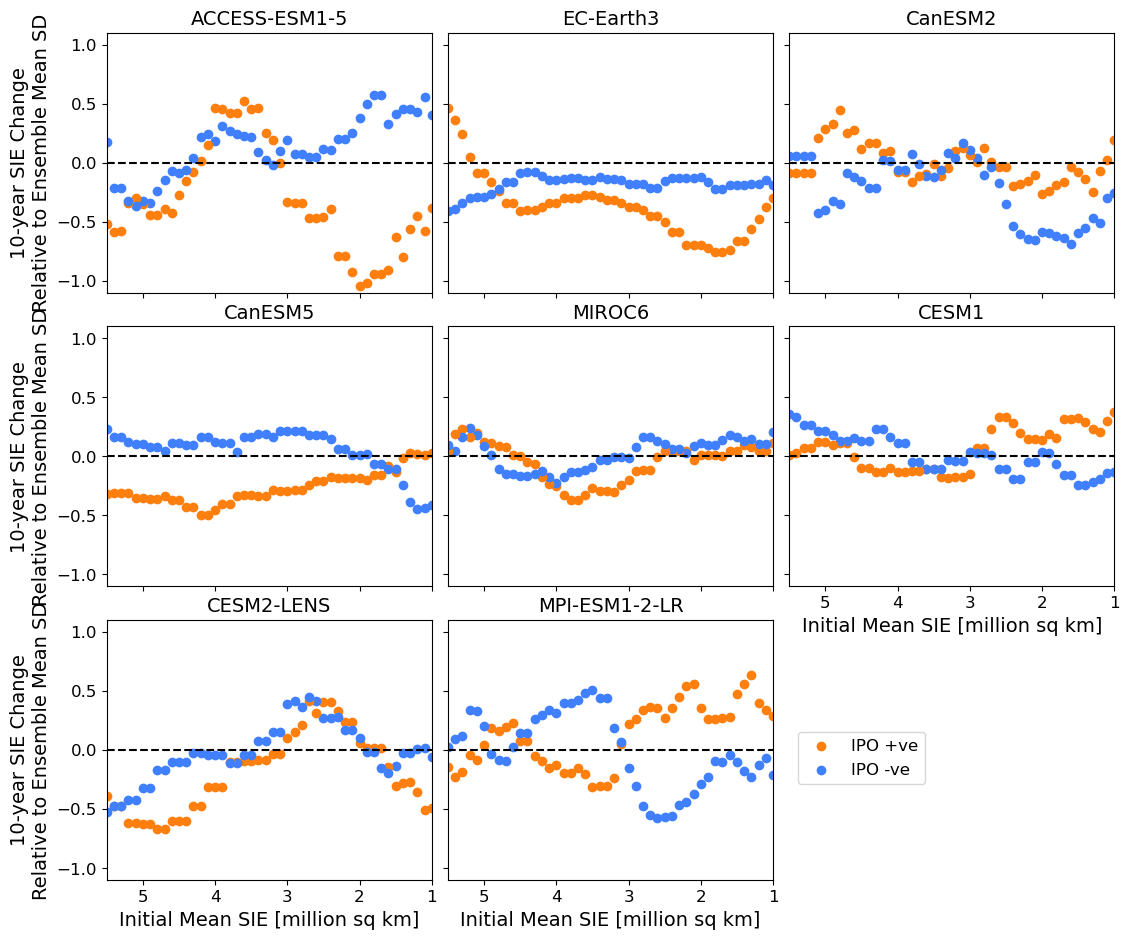

In [104]:
fig, ax = plt.subplots(3,3,figsize=[13,11])

for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):
    
    ax_x = int(model_i%3)
    ax_y = int(np.floor(model_i/3))

    for i,init_SIE in enumerate(np.arange(1,6.1,0.1)):
        if i ==0:
            ax[ax_x][ax_y].scatter(init_SIE, IPO_pos_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c='tab:orange', label='IPO +ve')
            ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c=[0.25,0.5,1], label='IPO -ve')
        else:
            ax[ax_x][ax_y].scatter(init_SIE, IPO_pos_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c='tab:orange')
            ax[ax_x][ax_y].scatter(init_SIE, IPO_neg_dict[model_name][i].mean()/ens_sd_dict[model_name][i], c=[0.25,0.5,1])
    
    ax[ax_x][ax_y].set_ylim(-1.1,1.1)
    ax[ax_x][ax_y].set_xlim(1,5.5)        
            
    ax[ax_x][ax_y].axhline(0, c='k',linestyle='--')
    ax[ax_x][ax_y].set_title(model_name, fontsize=16);
    
    if model_i < 3:
        ax[ax_x][ax_y].set_ylabel('10-year SIE Change'+'\n'+'Relative to Ensemble Mean SD', fontsize=14)
    else:
        ax[ax_x][ax_y].set_yticklabels([])
    
    if model_i in [2,5,7]:
        ax[ax_x][ax_y].set_xlabel('Initial Mean SIE [million sq km]', fontsize=14)
    else:
        ax[ax_x][ax_y].set_xlabel([])
        ax[ax_x][ax_y].set_xticklabels([])
        ax[ax_x][ax_y].xaxis.label.set_color('1')
    
    ax[ax_x][ax_y].set_title(model_name, fontsize=14)
    ax[ax_x][ax_y].invert_xaxis()
    ax[ax_x][ax_y].tick_params(axis='both', which='major', labelsize=12)
    
ax[2][2].remove()
plt.subplots_adjust(wspace=0.05, hspace=0.13)

#add legend
plt.legend(fontsize=12, bbox_to_anchor=(1.05,0.6));

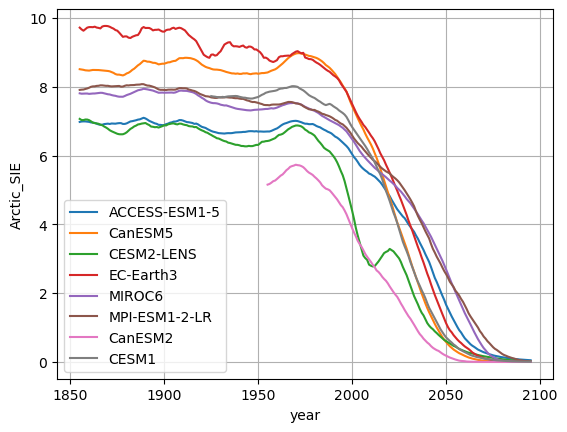

In [72]:
for model_name in ['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']:
    sep_SIE_11yr[model_name].mean('member').plot(label=model_name)

plt.legend()
plt.grid();

In [112]:
for model_name in ['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']:
    start_yr_LE = int(sep_SIE_11yr[model_name]['year'].where(
                    (sep_SIE_11yr[model_name].mean('member') - 4.7) < 0).min('year'))
    end_yr_LE = int(sep_SIE_11yr[model_name]['year'].where(
                    (sep_SIE_11yr[model_name].mean('member') - 1) < 0).min('year'))
    print(model_name, end_yr_LE - start_yr_LE)

ACCESS-ESM1-5 35
CanESM5 25
CESM2-LENS 43
EC-Earth3 25
MIROC6 34
MPI-ESM1-2-LR 35
CanESM2 41
CESM1 27


In [113]:
(35+25+43+25+34+35+41+27)/8

33.125

# Pooled IPO Trajectory and Spatial Plot

In [31]:
import cartopy.crs as ccrs
import matplotlib.path as mpath

In [15]:
#try normal t-test with sample size and SD of full ensemble to test if different from mean
p_val_IPO_only_pos = {}
p_val_IPO_only_neg = {}

for model_name in model_names[:-2]:
    
    n_mem = len(SIE_all_mem[model_name]['member'])

    p_val_IPO_only_model_pos  = []
    p_val_IPO_only_model_neg  = []

    for year_ in range(len(SIE_all_mem[model_name]['year'])):

        SD = SIE_all_mem[model_name].std('member').sel(year=year_)
        ens_mean = SIE_all_mem[model_name].mean('member').sel(year=year_)
    
        pos_mean = IPO_pos_dict[model_name].sel(year=year_)
        neg_mean = IPO_neg_dict[model_name].sel(year=year_)
        t = (pos_mean - ens_mean) / (SD/(n_mem**0.5))
        p_val_IPO_only_model_pos.append(stats.t.cdf(t, n_mem-1))
        t = (neg_mean - ens_mean) / (SD/(n_mem**0.5))
        p_val_IPO_only_model_neg.append(stats.t.cdf(t, n_mem-1))

    
    p_val_IPO_only_pos[model_name] = np.where(np.logical_or(0.025>np.array(p_val_IPO_only_model_pos), 
                                                            np.array(p_val_IPO_only_model_pos)>0.975),1,np.nan)
    p_val_IPO_only_neg[model_name] = np.where(np.logical_or(0.025>np.array(p_val_IPO_only_model_neg), 
                                                            np.array(p_val_IPO_only_model_neg)>0.975),1,np.nan)

In [18]:
#t-test with welch's method for different variances
p_val_IPO_only = {}

for model_name in model_names[:-2]:

    p_val_model = []

    for year_ in range(len(IPO_pos_dict_m[model_name]['year'])):
    
        pos_mean = IPO_pos_dict_m[model_name].mean('member').mean('start_SIE').sel(year=year_)
        neg_mean = IPO_neg_dict_m[model_name].mean('member').mean('start_SIE').sel(year=year_)
        neg_se = IPO_neg_dict_m[model_name].std('member').mean('start_SIE').sel(year=year_)/(len(IPO_neg_dict_m[model_name]['member']))**0.5
        pos_se = IPO_pos_dict_m[model_name].std('member').mean('start_SIE').sel(year=year_)/(len(IPO_neg_dict_m[model_name]['member']))**0.5
        
        welch_t = (pos_mean - neg_mean) / (pos_se**2+neg_se**2)**0.5
        p_val_model.append(stats.t.cdf(welch_t, np.min([len(IPO_neg_dict_m[model_name]['member']), len(IPO_pos_dict_m[model_name]['member'])])-1))
    
    p_val_IPO_only[model_name] = np.where(np.logical_or(0.025>np.array(p_val_model), 
                                                        np.array(p_val_model)>0.975),1,np.nan)

/glade/derecho/scratch/cwpowell/tmp/ipykernel_57355/1084640965.py:71: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[model_i].set_xticklabels([0, 10, 20, 30, 40, 50], fontsize=12, fontweight='bold')


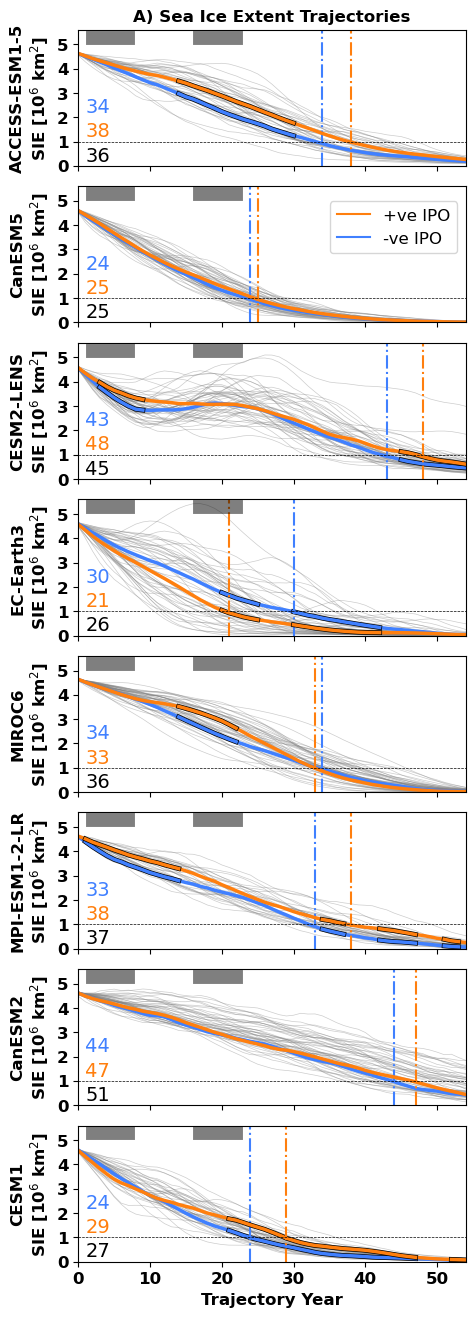

In [20]:
#Fig 2a, just the IPO on its own
#column 1 - sep by IPO, sep by PARC, sep by IPO for -ve PARC, sep by IPO for +ve PARC
fig, ax = plt.subplots(8,1,figsize=[5,16])

for model_i, model_name in enumerate(
    ['ACCESS-ESM1-5','CanESM5','CESM2-LENS','EC-Earth3',
     'MIROC6','MPI-ESM1-2-LR','CanESM2','CESM1']):

    #list the ensemble mean IF year
    IF_in_phase = int(SIE_all_mem[model_name]['year'].where(
        (SIE_all_mem[model_name].mean('member') - 1) < 0).min())
    ax[model_i].text(1, 0.2, str(IF_in_phase), color='k', fontsize=14)
    
   ### COLUMN 1 - plot the general IPO phase 
    SIE_all_mem[model_name].plot.line(
        x='year', ax=ax[model_i], add_legend=False, c='0.5', 
        linewidth=0.5, alpha=0.4)

    IPO_neg_dict[model_name].plot(ax=ax[model_i],c=[0.25,0.5,1],linewidth=2.5)
        
    IPO_neg_dict[model_name].where(p_val_IPO_only[model_name]==1).plot(
        ax=ax[model_i],c=[0.25,0.5,1],linewidth=2.5,
        path_effects=[pe.Stroke(linewidth=3.5, foreground='k'), pe.Normal()])

    try:
        IF_in_phase = int(IPO_neg_dict[model_name]['year'].where(
            (IPO_neg_dict[model_name] - 1) < 0).min())
        ax[model_i].text(1, 2.2 ,str(IF_in_phase), color=[0.25,0.5,1], fontsize=14)
        ax[model_i].axvline(IF_in_phase, linestyle='-.', color=[0.25,0.5,1])   
    except ValueError:
        print(model_name, 'does not go ice-free')
    
    IPO_pos_dict[model_name].plot(ax=ax[model_i],c='tab:orange',linewidth=2.5)

    IPO_pos_dict[model_name].where(p_val_IPO_only[model_name]==1).plot(
        ax=ax[model_i],c='tab:orange',linewidth=2.5,
        path_effects=[pe.Stroke(linewidth=3.5, foreground='k'), pe.Normal()])
    
    try:
        IF_in_phase = int(IPO_pos_dict[model_name]['year'].where(
            (IPO_pos_dict[model_name] - 1) < 0).min())
        ax[model_i].text(1, 1.2, str(IF_in_phase), color='tab:orange', fontsize=14)
        ax[model_i].axvline(IF_in_phase, linestyle='-.', color='tab:orange')   
    except ValueError:
        print(model_name, 'does not go ice-free')
    
    ax[model_i].axhline(1, c='k', linewidth=0.5, linestyle='--')
    ax[model_i].set_ylim(0, 5.6)
    ax[model_i].set_xlim(0, 54)            
    ax[model_i].set_title('')  

    ax[model_i].plot([2,7],[5.28,5.28], linewidth=10, c='k', alpha=0.5)
    ax[model_i].plot([17,22],[5.28,5.28], linewidth=10, c='k', alpha=0.5)

    #set axes parameters
    if model_i == 1:
        ax[model_i].plot([], [], c='tab:orange', label='+ve IPO')
        ax[model_i].plot([], [], c=[0.25,0.5,1], label='-ve IPO')
        ax[model_i].legend(fontsize=12, loc=[0.65, 0.51])

            
    ax[model_i].set_yticks([0, 1, 2, 3, 4, 5])
    ax[model_i].set_yticklabels([0, 1, 2, 3, 4, 5], fontsize=12, fontweight='bold')
    ax[model_i].set_ylabel(model_name+'\n'+'SIE [10$^6$ km$^2$]', 
                          fontsize=12, fontweight='bold')
    
    if model_i < 7:
        ax[model_i].set_xticklabels([])
        ax[model_i].set_xlabel('')
    else:
        ax[model_i].set_xticklabels([0, 10, 20, 30, 40, 50], fontsize=12, fontweight='bold')
        ax[model_i].set_xlabel('Trajectory Year', fontsize=12, fontweight='bold')

    if model_i == 0:
        ax[model_i].set_title('A) Sea Ice Extent Trajectories', fontsize=12, fontweight='bold')
    
plt.subplots_adjust(wspace=0.05, hspace=0.15)
plt.savefig('/glade/work/cwpowell/ice-free/figures/Fig_2a_IPO_SIE_traj_persitence_welch_signif.pdf',bbox_inches='tight')


In [23]:
#load the netcdf
path = '/glade/work/cwpowell/ice-free/SIC_trajectories/'

IPO_pos = {}
IPO_pos_SD = {}
IPO_pos_raw = {}
IPO_neg = {}
IPO_neg_SD = {}
IPO_neg_raw = {}
all_mem = {}
ens_max = {}
all_mem_SD = {}

for model_name in model_names[:-2]:
    
    IPO_pos[model_name] = xr.open_dataset(path+
        f'SIC_traj_IPO_pos_only_start_42_52_sq_km_{model_name}_regrid.nc')['SIC_trajectory'].sel(
        lat=slice(60,None))*100

    IPO_pos_SD[model_name] = xr.open_dataset(path+
        f'SIC_traj_IPO_pos_only_SD_start_42_52_sq_km_{model_name}_regrid.nc')['SIC_trajectory'].sel(
        lat=slice(60,None))*100

    IPO_pos_raw[model_name] = xr.open_dataset(path+
        f'SIC_traj_IPO_pos_only_SD_start_42_52_sq_km_{model_name}.nc').attrs['Members used']
    
    IPO_neg[model_name] = xr.open_dataset(path+
        f'SIC_traj_IPO_neg_only_start_42_52_sq_km_{model_name}_regrid.nc')['SIC_trajectory'].sel(
        lat=slice(60,None))*100

    IPO_neg_SD[model_name] = xr.open_dataset(path+
        f'SIC_traj_IPO_neg_only_SD_start_42_52_sq_km_{model_name}_regrid.nc')['SIC_trajectory'].sel(
        lat=slice(60,None))*100

    IPO_neg_raw[model_name] = xr.open_dataset(path+
        f'SIC_traj_IPO_neg_only_SD_start_42_52_sq_km_{model_name}.nc').attrs['Members used']
    
    all_mem[model_name] = xr.open_dataset(path+
        f'SIC_traj_ensemble_mean_start_42_52_sq_km_{model_name}_regrid.nc')['SIC_trajectory'].sel(
        lat=slice(60,None))*100

    ens_max[model_name] = xr.open_dataset(path+
        f'SIC_traj_ensemble_max_start_42_52_sq_km_{model_name}_regrid.nc')['SIC_trajectory'].sel(
        lat=slice(60,None))*100

    all_mem_SD[model_name] = xr.open_dataset(path+
        f'SIC_traj_ensemble_SD_start_42_52_sq_km_{model_name}_regrid.nc')['SIC_trajectory'].sel(
        lat=slice(60,None))*100

In [40]:
CanESM2_sftlf = xr.open_dataset('/glade/work/cwpowell/ice-free/SIC_trajectories/CanESM2_sftlf_regrid_1x1_deg.nc')
ones_pole_hole = (IPO_pos['CESM1'].mean('trajectory_year')*0+1).where(IPO_pos['CESM1']['lat']==89,0)

mem_n = {'ACCESS-ESM1-5':40, 'CanESM5':49, 'CESM2-LENS':50, 'CESM2-LENS-SMBB':50,
         'EC-Earth3':50, 'MIROC6':50, 'MPI-ESM1-2-LR':30, 'CanESM2':50, 'CESM1':40}

model_names_title = [
    'ACCESS-ESM1-5',
    'CanESM5     ',
    'CESM2-LENS   ',
    'EC-Earth3     ',
    'MIROC6       ',
    'MPI-ESM1-2-LR',
    'CanESM2     ',
    'CESM1       '
]

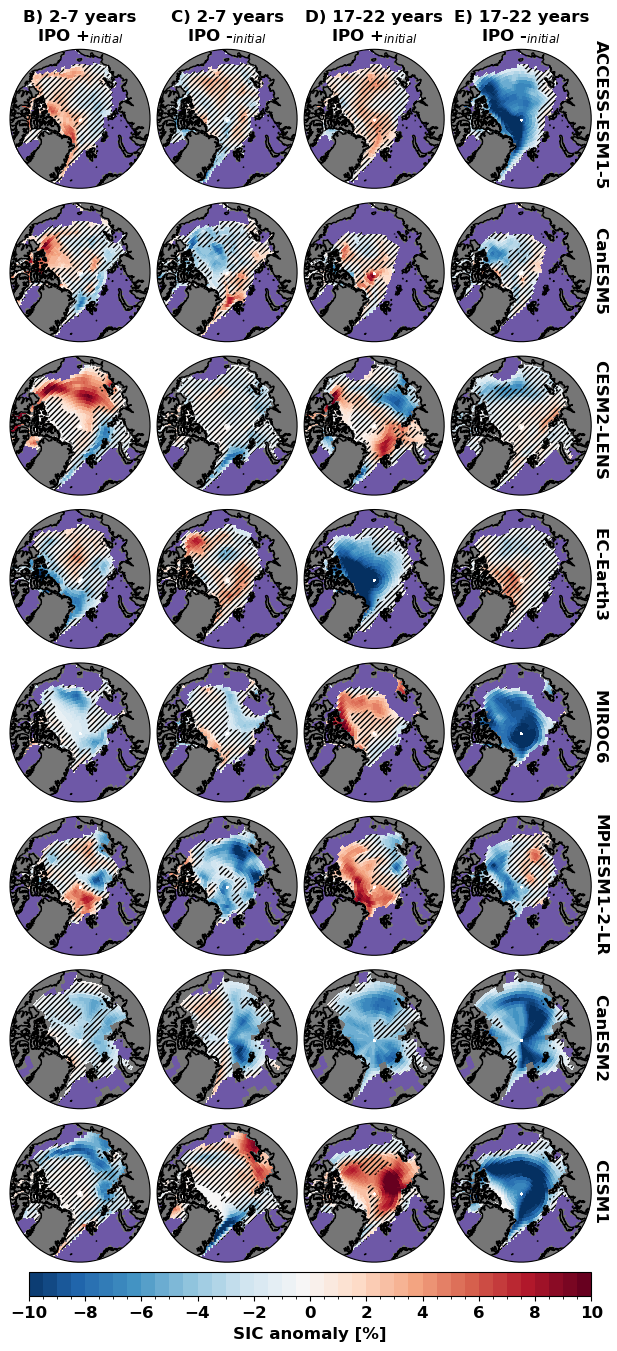

In [51]:
#remake figures 2B-E with significance testing from ensemble mean
#Figure 2 b,c polar plots of IPO irrespective of PARC
#significance from each other

lat_min = 68
levels_ = np.arange(-10,10.1,0.5)
title_list = ['B) 2-7 years'+'\n'+r'IPO +$_{initial}$', 
              'C) 2-7 years'+'\n'+'IPO -$_{initial}$',
              'D) 17-22 years'+'\n'+'IPO +$_{initial}$', 
              'E) 17-22 years'+'\n'+'IPO -$_{initial}$']

#this is the IF year
traj_start = [2,2,17,17]
traj_end = [7,7,22,22]

fig = plt.figure(figsize=[7.5,16])

for model_i, model_name in enumerate(
    ['ACCESS-ESM1-5', 'CanESM5', 'CESM2-LENS', 'EC-Earth3',
     'MIROC6', 'MPI-ESM1-2-LR', 'CanESM2', 'CESM1']):  

    data_use = [IPO_pos[model_name].copy(), IPO_neg[model_name].copy(),
                IPO_pos[model_name].copy(), IPO_neg[model_name].copy(),]

    for phase_i in range(4):

        ens_mean = all_mem[model_name].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')
    
        ens_sd = all_mem_SD[model_name].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')

        ens_max_model = ens_max[model_name].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')

        if model_name == 'CanESM2': #need to mask out the land
            ens_mean = ens_mean.where(CanESM2_sftlf['sftlf']==0)

        #calculate t-test  95% confidence interval
        n = mem_n[model_name] #the number of ensemble members
        se = ens_sd/(n**0.5) #the standard error    
        ens_95_CI = se * stats.t.ppf((1 + 0.95) / 2, n-1)
    
        ax = fig.add_subplot(8,4,(model_i*4 + phase_i+1), 
            projection = ccrs.NorthPolarStereo(central_longitude=0))
        ax.set_extent((-180,180,lat_min,90), ccrs.PlateCarree())

        #set boundary of subplots
        theta = np.linspace(0, 2*np.pi, 100) #make the plot circular
        center, radius = [0.5, 0.5], 0.5
        verts = np.vstack([np.sin(theta), np.cos(theta)]).T
        circle = mpath.Path(verts * radius + center)
        ax.set_boundary(circle, transform=ax.transAxes)
        ax.set_facecolor('1')

        #plot the land mask?
        # (np.isnan(ens_mean)==1).plot(cmap='gray_r',levels=np.arange(0.9,1.1,0.01))
        data_plot = (data_use[phase_i].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')-ens_mean)
        
        plotting = data_plot.plot(transform=ccrs.PlateCarree(), levels=levels_, 
                       add_colorbar=False)

        #plot stipiling where difference exceeds the 95% confidence interval
        sig_data = ((data_plot*0)+1).where(np.absolute(data_plot)<ens_95_CI)
        #or from each other
        # if phase_i <2:
        #     sig_data = ((data_plot*0)+1).where(p_val_IPO_2_7[model_name]!=1)
        # else:
        #     sig_data = ((data_plot*0)+1).where(p_val_IPO_15_25[model_name]!=1)
            
        ax.contourf(sig_data['lon'], sig_data['lat'], sig_data,
            transform=ccrs.PlateCarree(), colors='none', levels=[.5, 1.5], 
            hatches=['//////'], alpha=0)

        #color where no sea ice in purple?
        no_sea_ice = (ens_max_model.where(ens_max_model<15))*0 + 1
        no_sea_ice.plot(cmap='Purples_r', levels=np.arange(0.7,2,0.1), add_labels=False, 
                add_colorbar=False, transform=ccrs.PlateCarree(), 
                extend='neither', linewidths=0.0000000001, edgecolors='face')

        #shade land in gray
        land = (ens_mean>-999).where((ens_mean>-999)==0)
        land.plot(cmap='Greys_r', levels=np.arange(-0.5,1,0.1), add_labels=False, 
                add_colorbar=False, transform=ccrs.PlateCarree(), 
                extend='neither', linewidths=0.0000000001, edgecolors='face')
        
        if model_name == 'ACCESS-ESM1-5':
            ax.set_title(title_list[phase_i], fontweight='bold', fontsize=12)

        if phase_i == 3:
            ax.text(1.01, 0, model_names_title[model_i], fontsize=12,
                    fontweight='bold', transform=ax.transAxes, va='bottom', 
                    ha='left', rotation=270);

        ax.coastlines()        

cbar_ax = fig.add_axes([0.15, 0.095, 0.75, 0.015])
cb = fig.colorbar(plotting, cax=cbar_ax, ticks=np.arange(-10,10.1,2), spacing='uniform', 
                  extend='neither', orientation='horizontal')
cb.ax.set_xlabel('SIC anomaly [%]', fontsize=12, fontweight='bold', color='0') 
cbtick_obj = plt.getp(cb.ax.axes, 'xticklabels')   
plt.setp(cbtick_obj, color='0', fontsize=12, fontweight='bold')


plt.subplots_adjust(wspace=0.05, hspace=-0.03)
fig.savefig('/glade/work/cwpowell/ice-free/figures/IPO_spatial_2_7_17_22_years_with_sig.pdf',bbox_inches='tight')

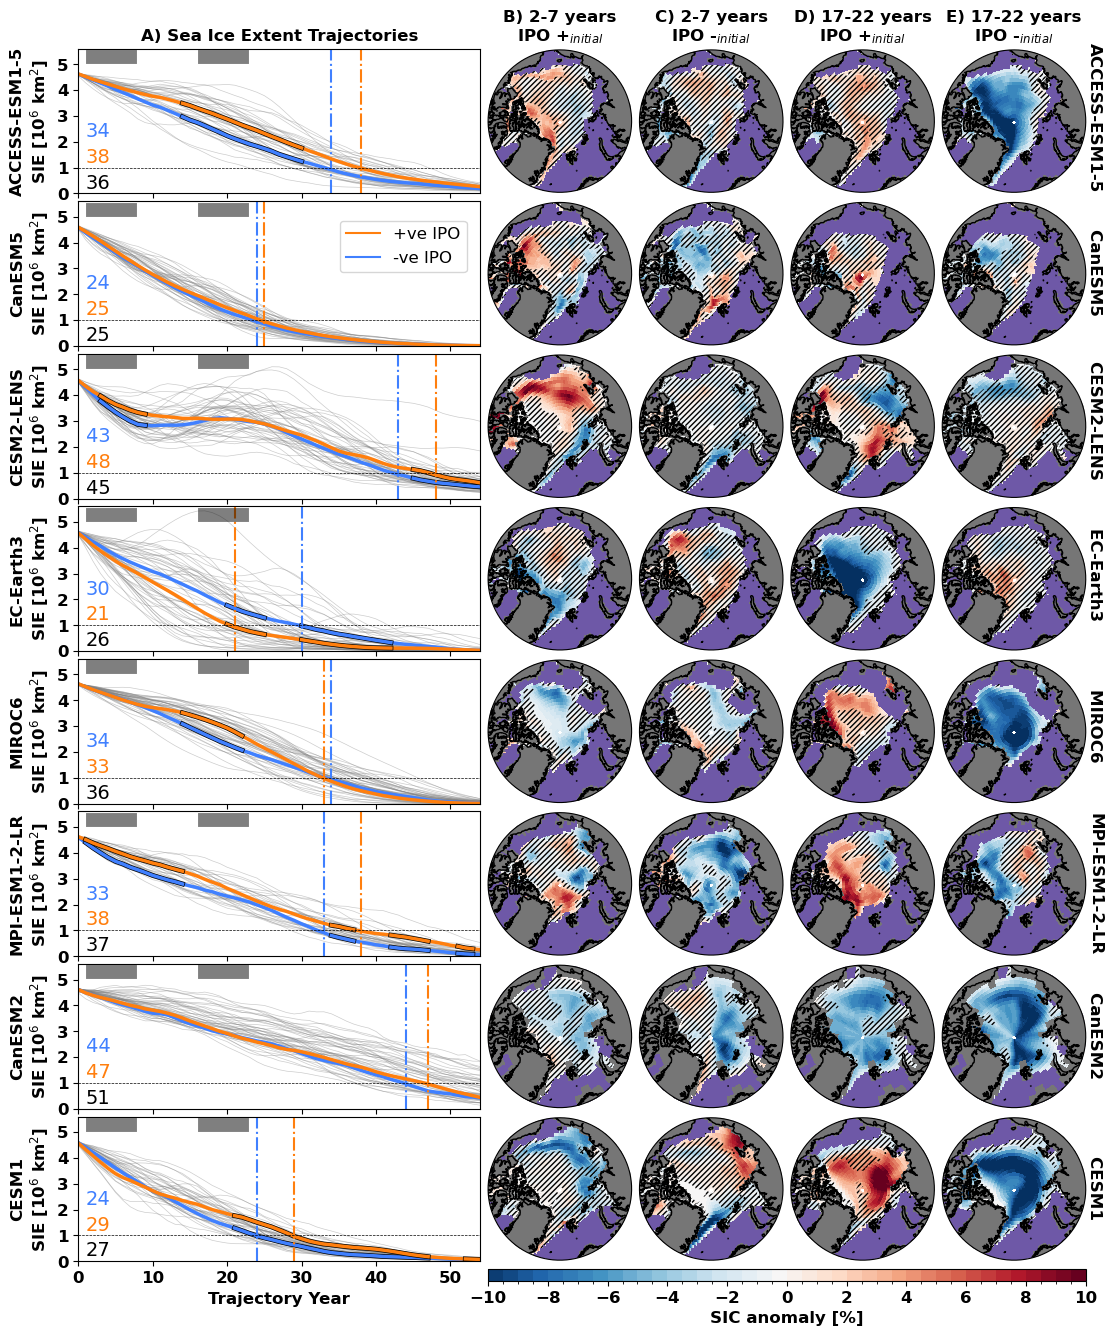

In [70]:
fig = plt.figure(figsize=(13,16))
gs = gridspec.GridSpec(
    9, 5,
    width_ratios=[2.8, 1, 1, 1, 1],
    height_ratios=[1,1,1,1,1,1,1,1,0.08],  # last row = colorbar
    wspace=0.04,
    hspace=0.06
)

#Figure 2a
for model_i, model_name in enumerate(
    ['ACCESS-ESM1-5','CanESM5','CESM2-LENS','EC-Earth3',
     'MIROC6','MPI-ESM1-2-LR','CanESM2','CESM1']):

    ax_ts = fig.add_subplot(gs[model_i, 0])

    #list the ensemble mean IF year
    IF_in_phase = int(SIE_all_mem[model_name]['year'].where(
        (SIE_all_mem[model_name].mean('member') - 1) < 0).min())
    ax_ts.text(1, 0.2, str(IF_in_phase), color='k', fontsize=14)
    
   ### COLUMN 1 - plot the general IPO phase 
    SIE_all_mem[model_name].plot.line(
        x='year', ax=ax_ts, add_legend=False, c='0.5', 
        linewidth=0.5, alpha=0.4)

    IPO_neg_dict[model_name].plot(ax=ax_ts,c=[0.25,0.5,1],linewidth=2.5)
        
    IPO_neg_dict[model_name].where(p_val_IPO_only[model_name]==1).plot(
        ax=ax_ts,c=[0.25,0.5,1],linewidth=2.5,
        path_effects=[pe.Stroke(linewidth=3.5, foreground='k'), pe.Normal()])

    try:
        IF_in_phase = int(IPO_neg_dict[model_name]['year'].where(
            (IPO_neg_dict[model_name] - 1) < 0).min())
        ax_ts.text(1, 2.2 ,str(IF_in_phase), color=[0.25,0.5,1], fontsize=14)
        ax_ts.axvline(IF_in_phase, linestyle='-.', color=[0.25,0.5,1])   
    except ValueError:
        print(model_name, 'does not go ice-free')
    
    IPO_pos_dict[model_name].plot(ax=ax_ts,c='tab:orange',linewidth=2.5)

    IPO_pos_dict[model_name].where(p_val_IPO_only[model_name]==1).plot(
        ax=ax_ts,c='tab:orange',linewidth=2.5,
        path_effects=[pe.Stroke(linewidth=3.5, foreground='k'), pe.Normal()])
    
    try:
        IF_in_phase = int(IPO_pos_dict[model_name]['year'].where(
            (IPO_pos_dict[model_name] - 1) < 0).min())
        ax_ts.text(1, 1.2, str(IF_in_phase), color='tab:orange', fontsize=14)
        ax_ts.axvline(IF_in_phase, linestyle='-.', color='tab:orange')   
    except ValueError:
        print(model_name, 'does not go ice-free')
    
    ax_ts.axhline(1, c='k', linewidth=0.5, linestyle='--')
    ax_ts.set_ylim(0, 5.6)
    ax_ts.set_xlim(0, 54)            
    ax_ts.set_title('')  

    ax_ts.plot([2,7],[5.28,5.28], linewidth=10, c='k', alpha=0.5)
    ax_ts.plot([17,22],[5.28,5.28], linewidth=10, c='k', alpha=0.5)

    #set axes parameters
    if model_i == 1:
        ax_ts.plot([], [], c='tab:orange', label='+ve IPO')
        ax_ts.plot([], [], c=[0.25,0.5,1], label='-ve IPO')
        ax_ts.legend(fontsize=12, loc=[0.65, 0.51])

            
    ax_ts.set_yticks([0, 1, 2, 3, 4, 5])
    ax_ts.set_yticklabels([0, 1, 2, 3, 4, 5], fontsize=12, fontweight='bold')
    ax_ts.set_ylabel(model_name+'\n'+'SIE [10$^6$ km$^2$]', 
                          fontsize=12, fontweight='bold')
    
    if model_i < 7:
        ax_ts.set_xticklabels([])
        ax_ts.set_xlabel('')
    else:
        ax_ts.set_xticks([0, 10, 20, 30, 40, 50])
        ax_ts.set_xticklabels([0, 10, 20, 30, 40, 50],
                              fontsize=12, fontweight='bold')
        ax_ts.set_xlabel('Trajectory Year', fontsize=12, fontweight='bold')

    if model_i == 0:
        ax_ts.set_title('A) Sea Ice Extent Trajectories', fontsize=12, fontweight='bold')


#Figure 2b-e
lat_min = 68
levels_ = np.arange(-10,10.1,0.5)
title_list = ['B) 2-7 years'+'\n'+r'IPO +$_{initial}$', 
              'C) 2-7 years'+'\n'+'IPO -$_{initial}$',
              'D) 17-22 years'+'\n'+'IPO +$_{initial}$', 
              'E) 17-22 years'+'\n'+'IPO -$_{initial}$']

#this is the IF year
traj_start = [2,2,17,17]
traj_end = [7,7,22,22]


for model_i, model_name in enumerate(
    ['ACCESS-ESM1-5', 'CanESM5', 'CESM2-LENS', 'EC-Earth3',
     'MIROC6', 'MPI-ESM1-2-LR', 'CanESM2', 'CESM1']):  

    data_use = [IPO_pos[model_name].copy(), IPO_neg[model_name].copy(),
                IPO_pos[model_name].copy(), IPO_neg[model_name].copy(),]

    for phase_i in range(4):

        ens_mean = all_mem[model_name].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')
    
        ens_sd = all_mem_SD[model_name].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')

        ens_max_model = ens_max[model_name].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')

        if model_name == 'CanESM2': #need to mask out the land
            ens_mean = ens_mean.where(CanESM2_sftlf['sftlf']==0)

        #calculate t-test  95% confidence interval
        n = mem_n[model_name] #the number of ensemble members
        se = ens_sd/(n**0.5) #the standard error    
        ens_95_CI = se * stats.t.ppf((1 + 0.95) / 2, n-1)
    
        ax = fig.add_subplot(
            gs[model_i, phase_i+1],
            projection=ccrs.NorthPolarStereo(central_longitude=0)
        )
        ax.set_extent((-180,180,lat_min,90), ccrs.PlateCarree())

        #set boundary of subplots
        theta = np.linspace(0, 2*np.pi, 100) #make the plot circular
        center, radius = [0.5, 0.5], 0.5
        verts = np.vstack([np.sin(theta), np.cos(theta)]).T
        circle = mpath.Path(verts * radius + center)
        ax.set_boundary(circle, transform=ax.transAxes)
        ax.set_facecolor('1')

        #plot the land mask?
        # (np.isnan(ens_mean)==1).plot(cmap='gray_r',levels=np.arange(0.9,1.1,0.01))
        data_plot = (data_use[phase_i].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')-ens_mean)
        
        plotting = data_plot.plot(transform=ccrs.PlateCarree(), levels=levels_, 
                       add_colorbar=False)

        #plot stipiling where difference exceeds the 95% confidence interval
        sig_data = ((data_plot*0)+1).where(np.absolute(data_plot)<ens_95_CI)
        #or from each other
        # if phase_i <2:
        #     sig_data = ((data_plot*0)+1).where(p_val_IPO_2_7[model_name]!=1)
        # else:
        #     sig_data = ((data_plot*0)+1).where(p_val_IPO_15_25[model_name]!=1)
            
        ax.contourf(sig_data['lon'], sig_data['lat'], sig_data,
            transform=ccrs.PlateCarree(), colors='none', levels=[.5, 1.5], 
            hatches=['//////'], alpha=0)

        #color where no sea ice in purple?
        no_sea_ice = (ens_max_model.where(ens_max_model<15))*0 + 1
        no_sea_ice.plot(cmap='Purples_r', levels=np.arange(0.7,2,0.1), add_labels=False, 
                add_colorbar=False, transform=ccrs.PlateCarree(), 
                extend='neither', linewidths=0.0000000001, edgecolors='face')

        #shade land in gray
        land = (ens_mean>-999).where((ens_mean>-999)==0)
        land.plot(cmap='Greys_r', levels=np.arange(-0.5,1,0.1), add_labels=False, 
                add_colorbar=False, transform=ccrs.PlateCarree(), 
                extend='neither', linewidths=0.0000000001, edgecolors='face')
        
        if model_name == 'ACCESS-ESM1-5':
            ax.set_title(title_list[phase_i], fontweight='bold', fontsize=12)

        if phase_i == 3:
            ax.text(1.01, 0, model_names_title[model_i], fontsize=12,
                    fontweight='bold', transform=ax.transAxes, va='bottom', 
                    ha='left', rotation=270);

        ax.coastlines()        

# cbar_ax = fig.add_axes([0.4, 0.095, 0.6, 0.015])
# cb = fig.colorbar(plotting, cax=cbar_ax, ticks=np.arange(-10,10.1,2), spacing='uniform', 
#                   extend='neither', orientation='horizontal')
cbar_ax = fig.add_subplot(gs[8, 1:5])  # only under maps
cb = fig.colorbar(plotting, cax=cbar_ax, extend='neither',
                  ticks=np.arange(-10,10.1,2), orientation='horizontal')
cb.ax.set_xlabel('SIC anomaly [%]', fontsize=12, fontweight='bold', color='0') 
cbtick_obj = plt.getp(cb.ax.axes, 'xticklabels')   
plt.setp(cbtick_obj, color='0', fontsize=12, fontweight='bold');

fig.savefig('/glade/work/cwpowell/ice-free/figures/Fig_2a_e_IPO_pooled_with_sig.pdf',bbox_inches='tight')